# Predicción de PM10 y PM2.5 usando Random Forest optimizado

Este notebook mejora el modelo **Random Forest** para intentar obtener predicciones más cercanas a los valores reales de **PM10** y **PM2.5**.

## Mejora metodológica incorporada

A diferencia de una versión básica de Random Forest, esta versión incluye:

1. **Mayor ingeniería de variables temporales**:
   - rezagos cortos, semanales y mensuales;
   - diferencias temporales;
   - medias móviles;
   - desviaciones móviles;
   - mínimos y máximos móviles;
   - covariables meteorológicas rezagadas;
   - transformación circular de `DViento`.

2. **Búsqueda de hiperparámetros** con validación temporal:
   - no se usa validación aleatoria;
   - se usa `TimeSeriesSplit`;
   - se selecciona la configuración con menor RMSE de validación.

3. **Comparación entre dos enfoques**:
   - `directo`: Random Forest predice directamente el contaminante;
   - `residual_persistencia`: Random Forest aprende la corrección frente al último valor observado.

4. **Comparación contra persistencia**:
   - la persistencia usa el último valor conocido como predicción;
   - se calcula si Random Forest mejora o no frente a ese modelo base.

5. **Particiones temporales evaluadas**:
   - 60% entrenamiento / 40% prueba;
   - 70% entrenamiento / 30% prueba;
   - 80% entrenamiento / 20% prueba;
   - 90% entrenamiento / 10% prueba.

6. **Exportación profesional**:
   - métricas completas;
   - métricas de prueba;
   - hiperparámetros candidatos;
   - hiperparámetros seleccionados;
   - predicciones;
   - importancia de variables;
   - sobreajuste;
   - tiempo total de ejecución.

> Nota metodológica: esta versión busca mejorar la precisión, pero no fuerza artificialmente el R² ni usa información futura. La mejora se hace mediante mejor representación temporal y selección de hiperparámetros con validación cronológica.

### Diagnóstico adicional incorporado
Se incluye el análisis de **residuales temporales** definido como observado menos predicho, tanto para el mejor escenario mostrado en el notebook como para todos los escenarios guardados en archivos de salida.


### Control automático de alineación temporal (V2)
La versión V2 incorpora diagnóstico de **desfase temporal** entre la serie observada y la predicción. El notebook **no desplaza artificialmente** las predicciones después de observar la prueba. En su lugar, calcula el lag de máxima correlación, penaliza el desfase durante la selección por validación temporal y conserva para visualización el escenario con mejor equilibrio entre error, R² y alineación temporal.


### Actualización V3
- Se generan figuras de **entrenamiento + prueba real + predicción** para cada escenario 60/40, 70/30, 80/20, 90/10 y horizontes 7, 30 y 90 días.
- Debajo de cada figura se muestra el **residual temporal** `Real - Predicción` sobre el mismo eje de fechas.
- Se exportan tiempos **acumulados y detallados por intervalo/escenario**, además del tiempo total del notebook.


In [25]:
# ============================================================
# INICIO DE MEDICIÓN DEL TIEMPO TOTAL DEL NOTEBOOK
# ============================================================

import time
from datetime import datetime

TIEMPO_INICIO_NOTEBOOK = time.perf_counter()
FECHA_HORA_INICIO_NOTEBOOK = datetime.now()

print("Inicio de ejecución del notebook:")
print(FECHA_HORA_INICIO_NOTEBOOK.strftime("%Y-%m-%d %H:%M:%S"))

Inicio de ejecución del notebook:
2026-08-13 00:23:37


In [26]:

# ============================================================
# 1. LIBRERÍAS Y CONFIGURACIÓN GENERAL PARA CARGA/EDA
# ============================================================

import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

# Salidas exploratorias separadas de las salidas finales de modelado.
SALIDAS = Path("salidas_EDA_PM10_PM25")
GRAFICAS = SALIDAS / "graficas"
TABLAS = SALIDAS / "tablas"
GRAFICAS.mkdir(parents=True, exist_ok=True)
TABLAS.mkdir(parents=True, exist_ok=True)

print("Carpeta actual:", Path.cwd())
print("Salidas EDA:", SALIDAS.resolve())


Carpeta actual: C:\Users\santi\Prediccion_Cali_3_Version
Salidas EDA: C:\Users\santi\Prediccion_Cali_3_Version\salidas_EDA_PM10_PM25


In [27]:
# ============================================================
# 2. LOCALIZAR ARCHIVOS DE ENTRADA
# ============================================================

def buscar_archivo(patrones):
    carpeta = Path.cwd()

    for patron in patrones:
        ruta = carpeta / patron
        if ruta.exists():
            return ruta

        encontrados = sorted(carpeta.glob(patron))
        if encontrados:
            return encontrados[0]

    raise FileNotFoundError(f"No se encontró ningún archivo con estos patrones: {patrones}")


ARCHIVOS = {
    "PM10": buscar_archivo([
        "PM10_DATASET_FINAL_IMPUTADO.csv",
        "PM10_dataset_completo_final_con_atipicos.csv",
        "PM10_dataset_completo_final_imputado_RF_atipicos*.csv",
        "PM10_dataset_completo_final*.csv",
        "PM10_dataset_completo*.csv",
        "PM10.csv",
        "PM10*.csv"
    ]),
    "PM25": buscar_archivo([
        "PM25_DATASET_FINAL_IMPUTADO.csv",
        "PM2.5_DATASET_FINAL_IMPUTADO.csv",
        "PM25_dataset_completo_final_con_atipicos.csv",
        "PM2.5_dataset_completo_final_con_atipicos.csv",
        "PM25_dataset_completo_final_imputado_RF_atipicos*.csv",
        "PM2.5_dataset_completo_final_imputado_RF_atipicos*.csv",
        "PM25_dataset_completo_final*.csv",
        "PM2.5_dataset_completo_final*.csv",
        "PM25_dataset_completo*.csv",
        "PM2.5_dataset_completo*.csv",
        "PM25.csv",
        "PM2.5.csv",
        "PM25*.csv",
        "PM2.5*.csv"
    ]),
    "DViento": buscar_archivo([
        "DViento_DATASET_FINAL_IMPUTADO.csv",
        "DViento_dataset_completo_final_con_atipicos.csv",
        "DViento_dataset_completo_final*.csv",
        "DViento.csv",
        "DViento*.csv"
    ]),
    "HAire10": buscar_archivo([
        "HAire10_DATASET_FINAL_IMPUTADO.csv",
        "HAire10_dataset_completo_final_con_atipicos.csv",
        "HAire10_dataset_completo_final*.csv",
        "HAire10.csv",
        "HAire10*.csv"
    ]),
    "P": buscar_archivo([
        "P_DATASET_FINAL_IMPUTADO.csv",
        "P_dataset_completo_final_con_atipicos.csv",
        "P_dataset_completo_final*.csv",
        "P.csv",
        "P*.csv"
    ]),
    "RGlobal": buscar_archivo([
        "RGlobal_DATASET_FINAL_IMPUTADO.csv",
        "RGlobal_dataset_completo_final_con_atipicos.csv",
        "RGlobal_dataset_completo_final*.csv",
        "RGlobal.csv",
        "RGlobal*.csv"
    ]),
    "TMPR_AIR_10CM": buscar_archivo([
        "TMPR_AIR_10CM_DATASET_FINAL_IMPUTADO.csv",
        "TMPR_AIR_10CM_dataset_completo_final_con_atipicos.csv",
        "TMPR_AIR_10CM_dataset_completo_final*.csv",
        "TMPR AIR 10CM.csv",
        "TMPR_AIR_10CM.csv",
        "TMPR*.csv"
    ]),
    "VViento": buscar_archivo([
        "VViento_DATASET_FINAL_IMPUTADO.csv",
        "VViento_dataset_completo_final_con_atipicos.csv",
        "VViento_dataset_completo_final*.csv",
        "VViento.csv",
        "VViento*.csv"
    ])
}

display(Markdown("## Archivos detectados"))
for variable, ruta in ARCHIVOS.items():
    print(f"{variable}: {ruta}")

## Archivos detectados

PM10: C:\Users\santi\Prediccion_Cali_3_Version\PM10_dataset_completo_final.csv
PM25: C:\Users\santi\Prediccion_Cali_3_Version\PM25_dataset_completo_final.csv
DViento: C:\Users\santi\Prediccion_Cali_3_Version\DViento_dataset_completo_final.csv
HAire10: C:\Users\santi\Prediccion_Cali_3_Version\HAire10_dataset_completo_final.csv
P: C:\Users\santi\Prediccion_Cali_3_Version\P_dataset_completo_final.csv
RGlobal: C:\Users\santi\Prediccion_Cali_3_Version\RGlobal_dataset_completo_final.csv
TMPR_AIR_10CM: C:\Users\santi\Prediccion_Cali_3_Version\TMPR AIR 10CM_dataset_completo_final.csv
VViento: C:\Users\santi\Prediccion_Cali_3_Version\VViento_dataset_completo_final.csv


In [28]:
# ============================================================
# 3. FUNCIONES DE CARGA Y PREPARACIÓN
#    CORREGIDAS PARA PM2.5 / PM25 Y DATASETS FINALES IMPUTADOS
# ============================================================

def leer_csv_limpio(ruta):
    """
    Lee CSV en UTF-8 o Latin-1 y limpia nombres de columnas.
    """
    try:
        df = pd.read_csv(ruta)
    except UnicodeDecodeError:
        df = pd.read_csv(ruta, encoding="latin1")

    df.columns = [
        str(col).strip().replace("\ufeff", "")
        for col in df.columns
    ]

    return df


def normalizar_nombre_columna(nombre):
    """
    Normaliza nombres para encontrar columnas aunque tengan puntos,
    espacios, guiones, tildes o diferencias de mayúsculas.
    """
    nombre = str(nombre).strip().lower()
    nombre = nombre.replace("\ufeff", "")
    reemplazos = {
        "á": "a", "é": "e", "í": "i", "ó": "o", "ú": "u", "ñ": "n"
    }
    for a, b in reemplazos.items():
        nombre = nombre.replace(a, b)

    for ch in [".", "_", "-", " ", "/", "\\", "(", ")", "[", "]"]:
        nombre = nombre.replace(ch, "")

    return nombre


def buscar_columna_por_alias(df, alias):
    """
    Busca una columna usando una lista de alias posibles.
    """
    mapa = {
        normalizar_nombre_columna(col): col
        for col in df.columns
    }

    for a in alias:
        a_norm = normalizar_nombre_columna(a)
        if a_norm in mapa:
            return mapa[a_norm]

    for col in df.columns:
        col_norm = normalizar_nombre_columna(col)
        for a in alias:
            a_norm = normalizar_nombre_columna(a)
            if a_norm == col_norm:
                return col

    return None


def alias_variable(variable):
    """
    Alias aceptados para datasets originales y datasets finales imputados.
    """
    if variable == "PM25":
        return [
            "PM25",
            "PM2.5",
            "PM2_5",
            "PM 2.5",
            "PM2.5_final",
            "PM25_final",
            "PM2.5_RF_final",
            "PM25_RF_final",
            "PM2.5_limpio_sin_atipicos",
            "PM25_limpio_sin_atipicos"
        ]

    if variable == "PM10":
        return [
            "PM10",
            "PM10_final",
            "PM10_RF_final",
            "PM10_limpio_sin_atipicos"
        ]

    if variable == "TMPR_AIR_10CM":
        return [
            "TMPR_AIR_10CM",
            "TMPR AIR 10CM",
            "TMPR_AIR_10CM_final",
            "Temperatura aire 10cm",
            "Temperatura"
        ]

    return [
        variable,
        f"{variable}_final",
        f"{variable}_RF_final",
        f"{variable}_limpio_sin_atipicos"
    ]


def preparar_variable(ruta, variable):
    """
    Prepara una variable para integrarla a la base maestra.

    Correcciones:
    - Acepta PM2.5 aunque el notebook trabaje internamente con PM25.
    - Acepta columnas finales imputadas.
    - Convierte la variable a numérica.
    """
    df = leer_csv_limpio(ruta)

    col_estacion = buscar_columna_por_alias(
        df,
        ["Estacion", "Estación", "Nombre estacion", "Nombre de estación"]
    )

    col_fecha = buscar_columna_por_alias(
        df,
        ["Fecha inicial", "Fecha", "fecha", "Date", "date"]
    )

    col_variable = buscar_columna_por_alias(
        df,
        alias_variable(variable)
    )

    faltantes = []
    if col_estacion is None:
        faltantes.append("Estacion")
    if col_fecha is None:
        faltantes.append("Fecha inicial")
    if col_variable is None:
        faltantes.append(variable)

    if faltantes:
        print("Columnas disponibles:")
        print(df.columns.tolist())
        print("Alias buscados para la variable:", alias_variable(variable))
        raise KeyError(f"En el archivo de {variable} faltan estas columnas: {faltantes}")

    df = df.rename(columns={
        col_estacion: "Estacion",
        col_fecha: "Fecha inicial",
        col_variable: variable
    })

    df["Estacion"] = df["Estacion"].astype(str).str.strip().str.upper()
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
    df[variable] = pd.to_numeric(df[variable], errors="coerce")

    df = df[["Estacion", "Fecha inicial", variable]].copy()
    df = df.dropna(subset=["Estacion", "Fecha inicial"])
    df = (
        df.groupby(["Estacion", "Fecha inicial"], as_index=False)[variable]
        .mean()
        .sort_values(["Estacion", "Fecha inicial"])
        .reset_index(drop=True)
    )

    return df

In [29]:
# ============================================================
# 4. CARGA E INTEGRACIÓN DE LA BASE MAESTRA
# ============================================================

base = None

for variable, ruta in ARCHIVOS.items():
    df_variable = preparar_variable(ruta, variable)

    display(Markdown(f"### Vista inicial: {variable}"))
    display(df_variable.head())
    print("Filas:", len(df_variable))
    print("Estaciones:", df_variable["Estacion"].unique())
    print("Fecha mínima:", df_variable["Fecha inicial"].min())
    print("Fecha máxima:", df_variable["Fecha inicial"].max())
    print("-" * 80)

    if base is None:
        base = df_variable.copy()
    else:
        base = base.merge(
            df_variable,
            on=["Estacion", "Fecha inicial"],
            how="outer"
        )

base = base.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

display(Markdown("## Base maestra integrada"))
display(base.head())
display(base.tail())

print("Dimensión base maestra:", base.shape)

base.to_csv(TABLAS / "base_maestra_prediccion_PM10_PM25.csv", index=False, encoding="utf-8-sig")

### Vista inicial: PM10

,Estacion,Fecha inicial,PM10
0,PALMIRA,2022-01-01,28.779167
1,PALMIRA,2022-01-02,26.645833
2,PALMIRA,2022-01-03,28.575000
3,PALMIRA,2022-01-04,31.741667
4,PALMIRA,2022-01-05,31.750000


Filas: 365
Estaciones: ['PALMIRA']
Fecha mínima: 2022-01-01 00:00:00
Fecha máxima: 2022-12-31 00:00:00
--------------------------------------------------------------------------------


### Vista inicial: PM25

,Estacion,Fecha inicial,PM25
0,PALMIRA,2022-01-01,12.520833
1,PALMIRA,2022-01-02,6.350000
2,PALMIRA,2022-01-03,7.825000
3,PALMIRA,2022-01-04,7.645833
4,PALMIRA,2022-01-05,8.879167


...

Filas: 365
Estaciones: ['PALMIRA']
Fecha mínima: 2022-01-01 00:00:00
Fecha máxima: 2022-12-31 00:00:00
--------------------------------------------------------------------------------


## Base maestra integrada

,Estacion,Fecha inicial,PM10,PM25,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento
0,PALMIRA,2022-01-01,28.779167,12.520833,132.583333,84.366667,674.733333,81.258333,22.791667,1.245833
1,PALMIRA,2022-01-02,26.645833,6.350000,136.625000,74.720833,675.304167,126.820833,24.291667,1.300000
2,PALMIRA,2022-01-03,28.575000,7.825000,143.083333,86.337500,675.820833,98.195833,22.570833,0.933333
3,PALMIRA,2022-01-04,31.741667,7.645833,206.166667,77.820833,674.791667,128.458333,23.500000,1.316667
4,PALMIRA,2022-01-05,31.750000,8.879167,210.291667,79.095833,673.908333,106.945833,23.308333,1.287500


,Estacion,Fecha inicial,PM10,PM25,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento
360,PALMIRA,2022-12-27,26.400000,8.850000,167.791667,78.766667,676.062500,123.587500,23.012500,1.283333
361,PALMIRA,2022-12-28,27.007304,9.500840,76.166667,84.050000,676.081551,50.545833,22.041667,1.271581
362,PALMIRA,2022-12-29,26.360911,9.348014,137.279314,79.933778,675.477465,101.501868,22.609474,1.267957
363,PALMIRA,2022-12-30,31.697121,10.929576,133.208333,63.315385,675.600116,88.341667,26.523077,1.104167
364,PALMIRA,2022-12-31,25.283333,9.350000,140.125000,88.258333,676.395833,78.108333,21.308333,1.216667


Dimensión base maestra: (365, 10)


In [30]:
# ============================================================
# 5. REVISIÓN GENERAL DE DATOS
# ============================================================

variables_modelo = [
    "PM10",
    "PM25",
    "DViento",
    "HAire10",
    "P",
    "RGlobal",
    "TMPR_AIR_10CM",
    "VViento"
]

display(Markdown("## Revisión de columnas"))
display(pd.DataFrame({
    "Columna": base.columns,
    "Tipo": [base[col].dtype for col in base.columns],
    "Faltantes": [base[col].isna().sum() for col in base.columns]
}))

display(Markdown("## Resumen por estación"))
resumen_estacion = (
    base.groupby("Estacion")
    .agg(
        fecha_min=("Fecha inicial", "min"),
        fecha_max=("Fecha inicial", "max"),
        registros=("Fecha inicial", "count")
    )
    .reset_index()
)

display(resumen_estacion)

display(Markdown("## Faltantes por variable"))
faltantes = base[["Estacion"] + variables_modelo].groupby("Estacion").apply(
    lambda x: x[variables_modelo].isna().sum()
).reset_index()

display(faltantes)

display(Markdown("## Control de ceros, negativos y faltantes"))
control_calidad = []

for estacion, df_est in base.groupby("Estacion"):
    for variable in variables_modelo:
        control_calidad.append({
            "Estacion": estacion,
            "Variable": variable,
            "Ceros": int((df_est[variable] == 0).sum()),
            "Negativos": int((df_est[variable] < 0).sum()),
            "Faltantes": int(df_est[variable].isna().sum()),
            "Registros": int(df_est[variable].shape[0])
        })

control_calidad = pd.DataFrame(control_calidad)
display(control_calidad)

control_calidad.to_csv(TABLAS / "control_calidad_ceros_negativos_faltantes.csv", index=False, encoding="utf-8-sig")

## Revisión de columnas

,Columna,Tipo,Faltantes
0,Estacion,object,0
1,Fecha inicial,datetime64[ns],0
2,PM10,float64,0
3,PM25,float64,0
4,DViento,float64,0
5,HAire10,float64,0
6,P,float64,0
7,RGlobal,float64,0
8,TMPR_AIR_10CM,float64,0
9,VViento,float64,0


## Resumen por estación

,Estacion,fecha_min,fecha_max,registros
0,PALMIRA,2022-01-01,2022-12-31,365


## Faltantes por variable

,Estacion,PM10,PM25,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento
0,PALMIRA,0,0,0,0,0,0,0,0


## Control de ceros, negativos y faltantes

,Estacion,Variable,Ceros,Negativos,Faltantes,Registros
0,PALMIRA,PM10,0,0,0,365
1,PALMIRA,PM25,0,0,0,365
2,PALMIRA,DViento,0,0,0,365
3,PALMIRA,HAire10,0,0,0,365
4,PALMIRA,P,0,0,0,365
5,PALMIRA,RGlobal,0,0,0,365
6,PALMIRA,TMPR_AIR_10CM,0,0,0,365
7,PALMIRA,VViento,0,0,0,365


In [31]:
# ============================================================
# 6. ESTADÍSTICOS DESCRIPTIVOS
# ============================================================

display(Markdown("## Estadísticos descriptivos generales"))

estadisticos = (
    base.groupby("Estacion")[variables_modelo]
    .describe()
    .T
)

display(estadisticos)

estadisticos.to_csv(TABLAS / "estadisticos_descriptivos.csv", encoding="utf-8-sig")

display(Markdown("## Estadísticos en formato tabla por variable"))

estadisticos_tabla = []

for estacion, df_est in base.groupby("Estacion"):
    for variable in variables_modelo:
        serie = df_est[variable].dropna()
        estadisticos_tabla.append({
            "Estacion": estacion,
            "Variable": variable,
            "n": serie.count(),
            "Media": serie.mean(),
            "Mediana": serie.median(),
            "Desviacion_estandar": serie.std(),
            "Minimo": serie.min(),
            "Q1": serie.quantile(0.25),
            "Q3": serie.quantile(0.75),
            "Maximo": serie.max()
        })

estadisticos_tabla = pd.DataFrame(estadisticos_tabla)
display(estadisticos_tabla)

estadisticos_tabla.to_csv(TABLAS / "estadisticos_descriptivos_formato_tabla.csv", index=False, encoding="utf-8-sig")

## Estadísticos descriptivos generales

Estacion          PALMIRA
PM10    count  365.000000
        mean    29.722302
        std      8.242992
        min      8.416667
        25%     24.583333
...                   ...
VViento min      0.762500
        25%      1.141667
        50%      1.283333
        75%      1.416667
        max      1.866667

[64 rows x 1 columns]

## Estadísticos en formato tabla por variable

,Estacion,Variable,n,Media,Mediana,Desviacion_estandar,Minimo,Q1,Q3,Maximo
0,PALMIRA,PM10,365,29.722302,29.104167,8.242992,8.416667,24.583333,34.141667,61.704167
1,PALMIRA,PM25,365,10.590868,10.395833,2.255277,5.687500,9.025000,11.825000,20.487500
2,PALMIRA,DViento,365,155.871190,155.666667,21.024376,76.166667,142.888333,170.000000,243.000000
3,PALMIRA,HAire10,365,77.372660,76.870833,6.649829,62.775000,72.370833,81.487500,98.937500
4,PALMIRA,P,365,693.276091,675.477465,59.980287,673.250000,674.854167,676.129167,900.883333
5,PALMIRA,RGlobal,365,118.890552,119.504167,24.611760,43.866667,103.091667,136.762500,175.220833
6,PALMIRA,TMPR_AIR_10CM,365,23.471029,23.569565,1.135106,20.000000,22.729167,24.287500,26.523077
7,PALMIRA,VViento,365,1.281821,1.283333,0.200172,0.762500,1.141667,1.416667,1.866667


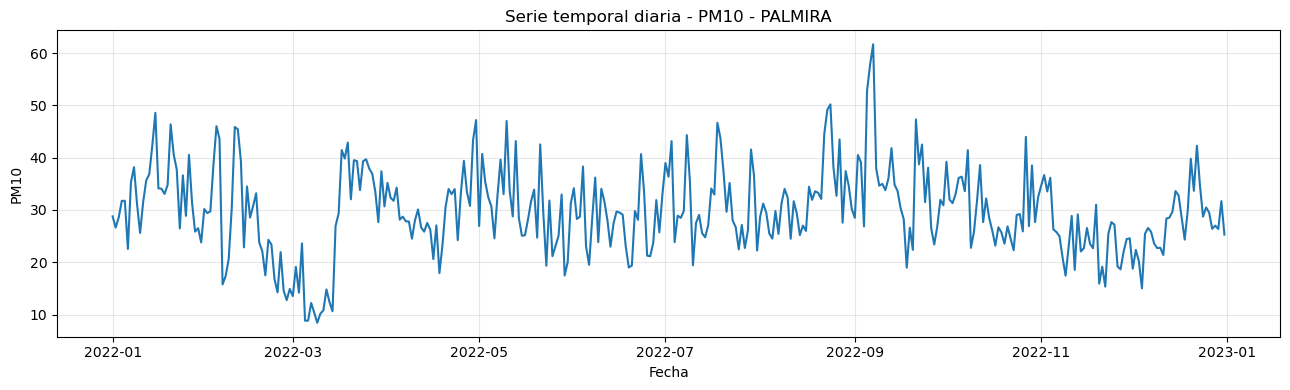

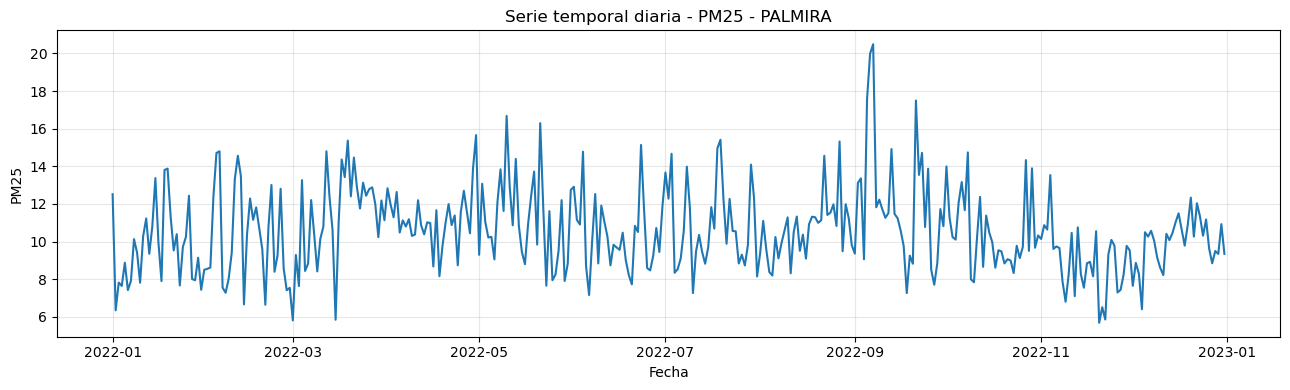

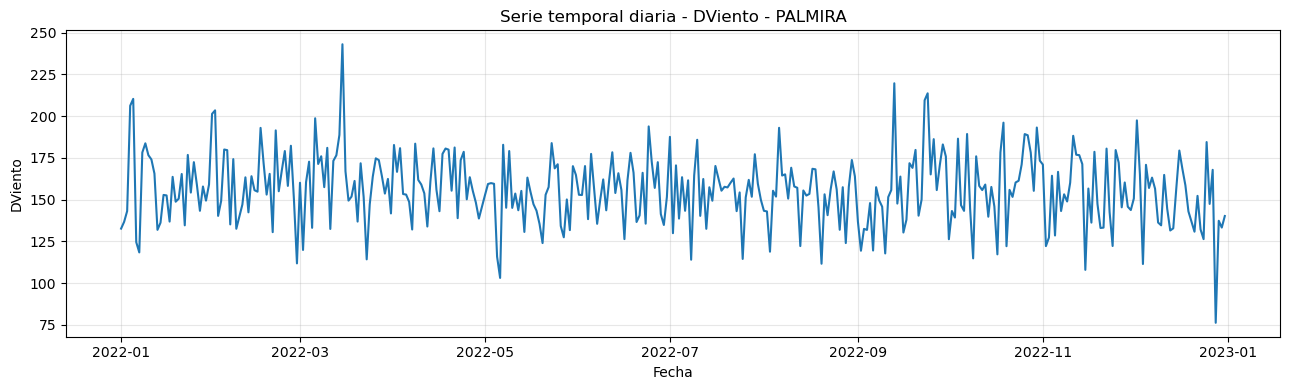

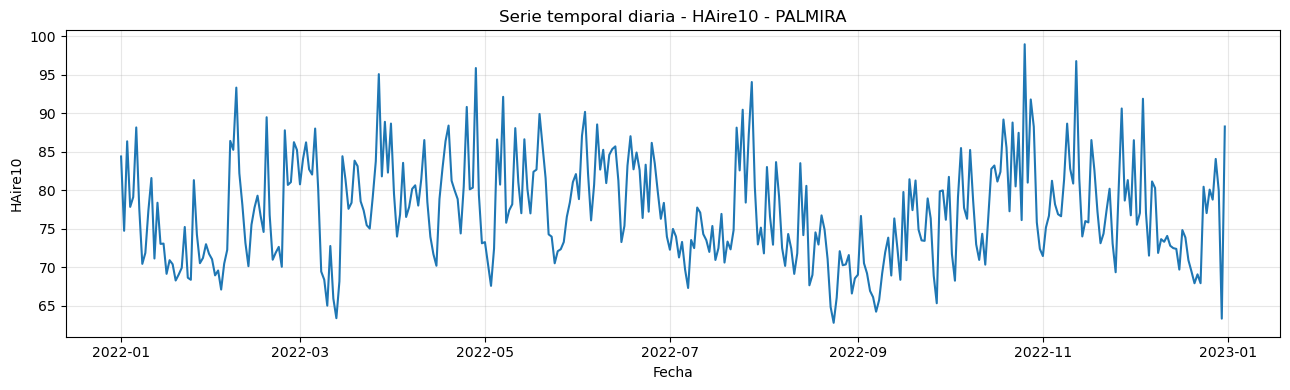

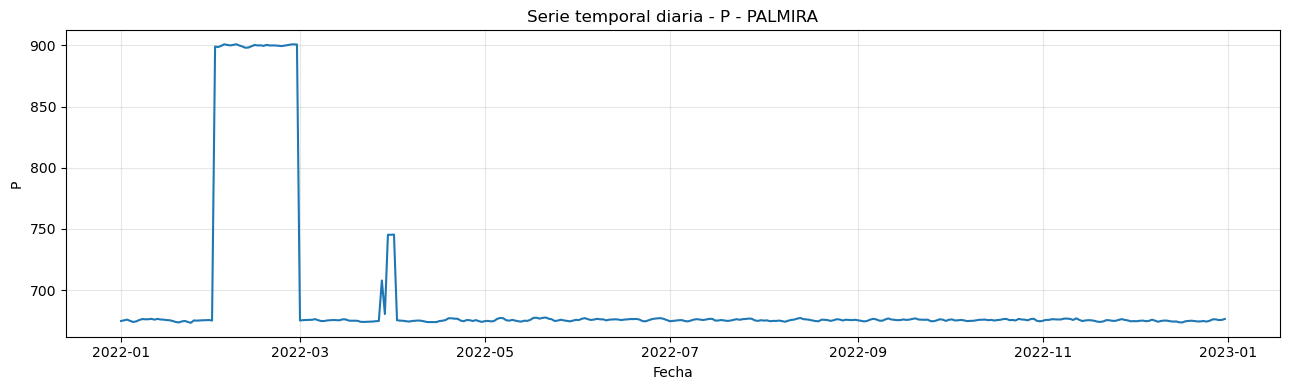

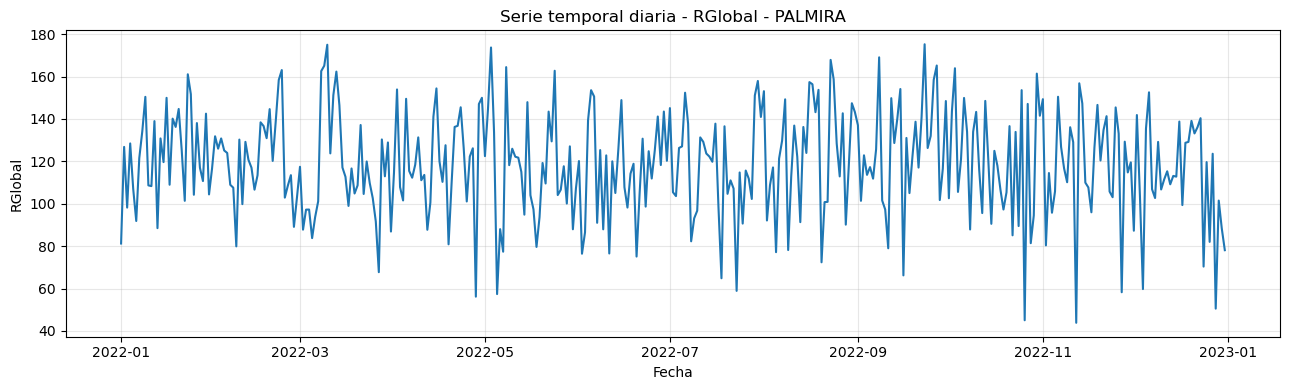

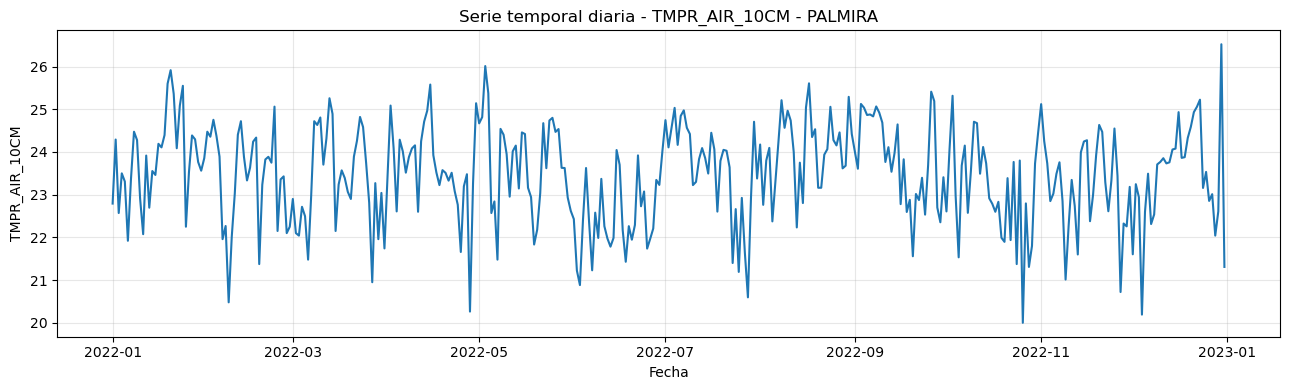

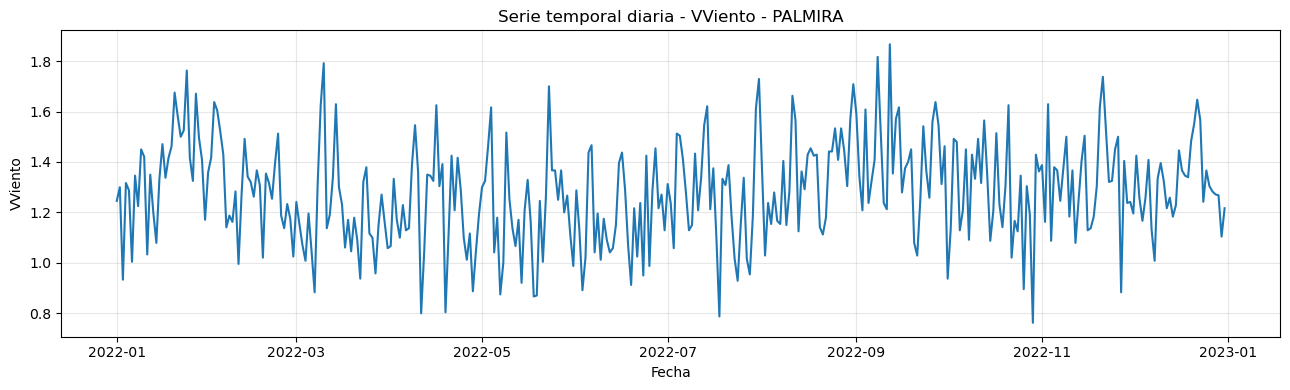

In [32]:
# ============================================================
# 7. GRÁFICAS EXPLORATORIAS DE SERIES TEMPORALES
# ============================================================

def nombre_seguro(texto):
    texto = str(texto)
    reemplazos = {
        " ": "_", "/": "_", ".": "",
        "Á": "A", "É": "E", "Í": "I", "Ó": "O", "Ú": "U", "Ñ": "N"
    }
    for a, b in reemplazos.items():
        texto = texto.replace(a, b)
    return texto


for estacion, df_est in base.groupby("Estacion"):
    df_est = df_est.sort_values("Fecha inicial")

    for variable in variables_modelo:
        plt.figure(figsize=(13, 4))
        plt.plot(df_est["Fecha inicial"], df_est[variable])
        plt.title(f"Serie temporal diaria - {variable} - {estacion}")
        plt.xlabel("Fecha")
        plt.ylabel(variable)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(GRAFICAS / f"serie_tiempo_{variable}_{nombre_seguro(estacion)}.png", dpi=160)
        plt.show()

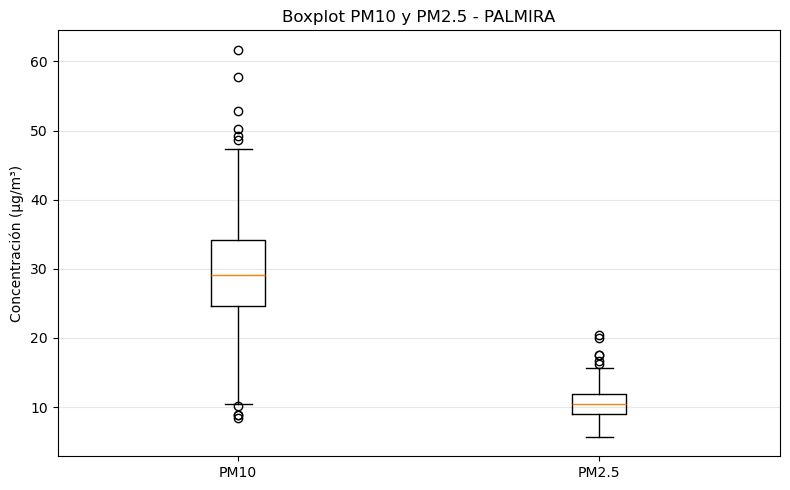

## Matriz de correlación - PALMIRA

,PM10,PM25,DViento,HAire10,P,RGlobal,TMPR_AIR_10CM,VViento
PM10,1.000000,0.778447,-0.044802,-0.275616,-0.088175,0.083136,0.277361,-0.026408
PM25,0.778447,1.000000,-0.003847,-0.170921,-0.025073,0.068090,0.185924,-0.205974
DViento,-0.044802,-0.003847,1.000000,-0.023718,0.054440,0.296981,0.025685,0.096690
HAire10,-0.275616,-0.170921,-0.023718,1.000000,0.025593,-0.620428,-0.886225,-0.644195
P,-0.088175,-0.025073,0.054440,0.025593,1.000000,0.022882,-0.036948,0.010543
RGlobal,0.083136,0.068090,0.296981,-0.620428,0.022882,1.000000,0.566554,0.563465
TMPR_AIR_10CM,0.277361,0.185924,0.025685,-0.886225,-0.036948,0.566554,1.000000,0.563300
VViento,-0.026408,-0.205974,0.096690,-0.644195,0.010543,0.563465,0.563300,1.000000


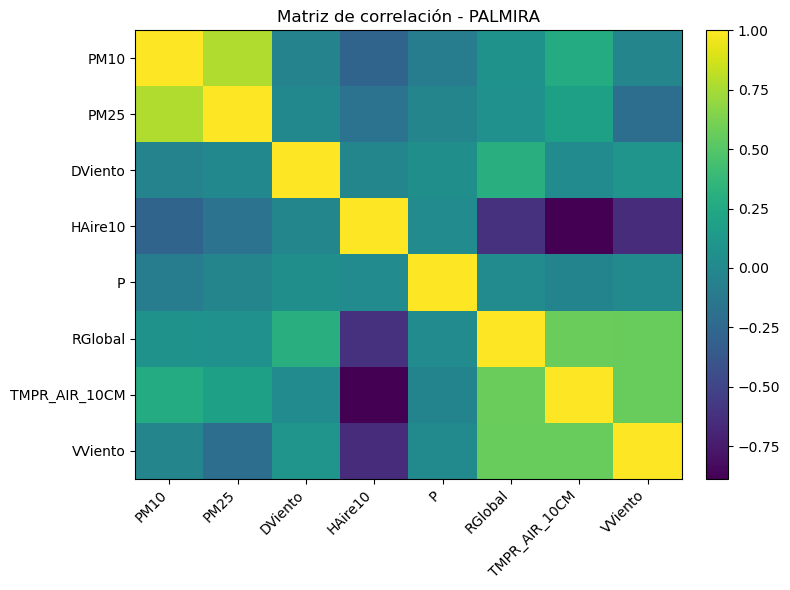

In [33]:
# ============================================================
# 8. BOXPLOTS Y MATRIZ DE CORRELACIÓN
# ============================================================

for estacion, df_est in base.groupby("Estacion"):
    df_est = df_est.sort_values("Fecha inicial")

    plt.figure(figsize=(8, 5))
    plt.boxplot(
        [df_est["PM10"].dropna(), df_est["PM25"].dropna()],
        tick_labels=["PM10", "PM2.5"]
    )
    plt.title(f"Boxplot PM10 y PM2.5 - {estacion}")
    plt.ylabel("Concentración (µg/m³)")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(GRAFICAS / f"boxplot_PM10_PM25_{nombre_seguro(estacion)}.png", dpi=160)
    plt.show()

    corr = df_est[variables_modelo].corr()

    display(Markdown(f"## Matriz de correlación - {estacion}"))
    display(corr)

    plt.figure(figsize=(8, 6))
    im = plt.imshow(corr, aspect="auto")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title(f"Matriz de correlación - {estacion}")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(GRAFICAS / f"correlacion_{nombre_seguro(estacion)}.png", dpi=160)
    plt.show()


## Protocolo de evaluación temporal para tesis

Este notebook usa un protocolo homogéneo para comparar los modelos de predicción de PM10 y PM2.5.

### Escenarios evaluados

1. **Sensibilidad a la partición temporal** con predicción a **1 día**:
   - 60 % entrenamiento / 40 % prueba.
   - 70 % entrenamiento / 30 % prueba.
   - 80 % entrenamiento / 20 % prueba.
   - 90 % entrenamiento / 10 % prueba.

2. **Horizontes directos de predicción**:
   - 7 días.
   - 30 días.
   - 90 días.

   Para aislar el efecto del horizonte, estos tres escenarios usan como referencia una partición nominal 80 % / 20 %.

### Controles metodológicos

- Las particiones son **cronológicas**; no se mezclan observaciones futuras con pasadas.
- Para un horizonte \(h\), la variable objetivo es \(y_{t+h}\); por tanto, 7, 30 y 90 días son **horizontes reales de pronóstico**, no solamente tamaños del conjunto de prueba.
- Se aplica una **purga temporal (gap) de \(h\) días** entre entrenamiento y prueba, y también dentro de la validación cruzada temporal.
- No se usa `bfill` ni interpolación bidireccional dentro de la etapa de modelado.
- Se incluye una línea base de **persistencia**: \(\hat{y}_{t+h}=y_t\).
- La selección de hiperparámetros se realiza únicamente con el conjunto de entrenamiento.
- Se registran por escenario los tiempos de validación, entrenamiento final, predicción y tiempo total.
- Se reportan MAE, RMSE, R², MAPE, sMAPE, WAPE, sesgo medio y mejora de RMSE frente a persistencia.

> **Nota:** debido a la purga temporal, el porcentaje efectivo de entrenamiento puede ser ligeramente inferior al porcentaje nominal. Ambos valores se reportan en las tablas finales.


In [34]:

# ============================================================
# 9. CONFIGURACIÓN DEL PROTOCOLO - RANDOM FOREST
# ============================================================

import json
import re
import platform
import sklearn
import matplotlib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE_RF = 42
N_FOLDS_RF = 5
TRAIN_FRAC_HORIZONTES = 0.80
MIN_TRAIN_RF = 120
MIN_TEST_RF = 20
CLIP_PREDICCIONES_CERO = True

# Control de alineación temporal para evitar modelos visualmente "corridos".
CONTROL_ALINEACION_TEMPORAL = True
# Pesos del score de validación: RMSE 55%, MAE 15%, desfase 20%, R² 10%.
PESOS_SCORE_CV_ALINEADO = {"RMSE": 0.55, "MAE": 0.15, "LAG": 0.20, "R2": 0.10}

# Escenarios solicitados por la tesis.
ESCENARIOS_RF = [
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "60_40_H1", "Train_nominal": 0.60, "Horizonte_dias": 1, "Orden": 1},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "70_30_H1", "Train_nominal": 0.70, "Horizonte_dias": 1, "Orden": 2},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "80_20_H1", "Train_nominal": 0.80, "Horizonte_dias": 1, "Orden": 3},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "90_10_H1", "Train_nominal": 0.90, "Horizonte_dias": 1, "Orden": 4},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_7_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 7, "Orden": 5},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_30_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 30, "Orden": 6},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_90_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 90, "Orden": 7},
]

# Se conserva la amplitud de la grilla original.
PARAM_GRID_RF = [
    {"n_estimators": 500, "max_depth": 8,  "min_samples_split": 2, "min_samples_leaf": 2, "max_features": "sqrt", "bootstrap": True},
    {"n_estimators": 700, "max_depth": 10, "min_samples_split": 2, "min_samples_leaf": 2, "max_features": "sqrt", "bootstrap": True},
    {"n_estimators": 700, "max_depth": 12, "min_samples_split": 4, "min_samples_leaf": 2, "max_features": 0.7,    "bootstrap": True},
    {"n_estimators": 900, "max_depth": 14, "min_samples_split": 4, "min_samples_leaf": 3, "max_features": 0.8,    "bootstrap": True},
    {"n_estimators": 900, "max_depth": None, "min_samples_split": 6, "min_samples_leaf": 3, "max_features": "sqrt", "bootstrap": True},
    {"n_estimators": 1200,"max_depth": 16, "min_samples_split": 6, "min_samples_leaf": 4, "max_features": 0.7,    "bootstrap": True},
]

TIPOS_MODELO_RF = ["directo", "residual_persistencia"]

REZAGOS_TARGET_RF = [1, 2, 3, 7, 14, 21, 30, 45, 60]
VENTANAS_TARGET_RF = [3, 7, 14, 21, 30, 45, 60]
REZAGOS_COV_RF = [1, 2, 3, 7, 14, 21, 30]
VENTANAS_COV_RF = [3, 7, 14]

SALIDAS_RF = Path("salidas_RF_TESIS_PROTOCOLO_TEMPORAL")
GRAFICAS_RF = SALIDAS_RF / "graficas"
TABLAS_RF = SALIDAS_RF / "tablas"
MODELOS_RF = SALIDAS_RF / "modelos"
for carpeta in [SALIDAS_RF, GRAFICAS_RF, TABLAS_RF, MODELOS_RF]:
    carpeta.mkdir(parents=True, exist_ok=True)

versiones_rf_df = pd.DataFrame([{
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "Semilla": RANDOM_STATE_RF
}])

escenarios_rf_df = pd.DataFrame(ESCENARIOS_RF)
hiperparametros_rf_df = pd.DataFrame(PARAM_GRID_RF).reset_index().rename(columns={"index": "id_config"})

display(Markdown("## Escenarios de evaluación"))
display(escenarios_rf_df)

display(Markdown("## Grilla candidata de hiperparámetros"))
display(hiperparametros_rf_df)

display(Markdown("## Entorno de ejecución"))
display(versiones_rf_df)


## Escenarios de evaluación

,Tipo_evaluacion,Escenario,Train_nominal,Horizonte_dias,Orden
0,Particion porcentual,60_40_H1,0.6,1,1
1,Particion porcentual,70_30_H1,0.7,1,2
2,Particion porcentual,80_20_H1,0.8,1,3
3,Particion porcentual,90_10_H1,0.9,1,4
4,Horizonte fijo,H_7_dias_80_20,0.8,7,5
5,Horizonte fijo,H_30_dias_80_20,0.8,30,6
6,Horizonte fijo,H_90_dias_80_20,0.8,90,7


## Grilla candidata de hiperparámetros

,id_config,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap
0,0,500,8.0,2,2,sqrt,True
1,1,700,10.0,2,2,sqrt,True
2,2,700,12.0,4,2,0.7,True
3,3,900,14.0,4,3,0.8,True
4,4,900,NaN,6,3,sqrt,True
5,5,1200,16.0,6,4,0.7,True


## Entorno de ejecución

,Python,numpy,pandas,scikit_learn,matplotlib,Semilla
0,3.13.5,2.1.3,2.2.3,1.6.1,3.10.0,42


In [35]:

# ============================================================
# 10. FUNCIONES DE PREPARACIÓN, MÉTRICAS Y VALIDACIÓN TEMPORAL
# ============================================================

def nombre_seguro_rf(texto):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(texto)).strip("_")


def calcular_metricas_tesis(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_real) & np.isfinite(y_pred)
    y_real, y_pred = y_real[mask], y_pred[mask]

    if len(y_real) == 0:
        return {k: np.nan for k in ["MAE", "RMSE", "R2", "MAPE_%", "sMAPE_%", "WAPE_%", "Sesgo_ME"]}

    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan

    mask_mape = np.abs(y_real) > 1e-8
    mape = np.mean(np.abs((y_real[mask_mape] - y_pred[mask_mape]) / y_real[mask_mape])) * 100 if mask_mape.any() else np.nan

    denom_smape = np.abs(y_real) + np.abs(y_pred)
    smape = np.mean(np.where(denom_smape > 1e-8, 2 * np.abs(y_pred - y_real) / denom_smape, np.nan)) * 100

    denom_wape = np.sum(np.abs(y_real))
    wape = (np.sum(np.abs(y_real - y_pred)) / denom_wape) * 100 if denom_wape > 1e-8 else np.nan
    sesgo = np.mean(y_pred - y_real)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_%": mape,
        "sMAPE_%": smape,
        "WAPE_%": wape,
        "Sesgo_ME": sesgo,
    }


def preparar_supervisado_rf(df_estacion, target, covariables, horizonte):
    """
    Construye X_t -> y_(t+h) usando únicamente información disponible
    hasta la fecha origen t. No se realizan imputaciones con información futura.
    """
    df = df_estacion.copy()
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
    df = df.dropna(subset=["Fecha inicial"]).sort_values("Fecha inicial")
    df = df.drop_duplicates(subset=["Fecha inicial"], keep="last").set_index("Fecha inicial").asfreq("D")

    columnas_numericas = [c for c in [target] + covariables if c in df.columns]
    df[columnas_numericas] = df[columnas_numericas].apply(pd.to_numeric, errors="coerce")

    # Fecha objetivo conocida de antemano.
    df["Fecha_objetivo"] = df.index + pd.to_timedelta(horizonte, unit="D")
    df["y_futuro"] = df[target].shift(-horizonte)

    # Valor actual del contaminante: disponible en la fecha origen.
    df[f"{target}_t0"] = df[target]

    # Rezagos del contaminante.
    for lag in REZAGOS_TARGET_RF:
        df[f"{target}_lag_{lag}"] = df[target].shift(lag)

    # Resúmenes móviles, siempre hasta t.
    for ventana in VENTANAS_TARGET_RF:
        r = df[target].rolling(ventana, min_periods=ventana)
        df[f"{target}_media_{ventana}"] = r.mean()
        df[f"{target}_std_{ventana}"] = r.std()
        df[f"{target}_min_{ventana}"] = r.min()
        df[f"{target}_max_{ventana}"] = r.max()

    # Tendencias históricas.
    df[f"{target}_diff_1"] = df[target] - df[target].shift(1)
    df[f"{target}_diff_7"] = df[target] - df[target].shift(7)

    # Calendario de la fecha que se quiere pronosticar.
    fecha_obj = pd.DatetimeIndex(df["Fecha_objetivo"])
    df["dow_obj_sin"] = np.sin(2 * np.pi * fecha_obj.dayofweek / 7)
    df["dow_obj_cos"] = np.cos(2 * np.pi * fecha_obj.dayofweek / 7)
    df["doy_obj_sin"] = np.sin(2 * np.pi * fecha_obj.dayofyear / 365.25)
    df["doy_obj_cos"] = np.cos(2 * np.pi * fecha_obj.dayofyear / 365.25)

    covs_modelo = [c for c in covariables if c in df.columns]

    if "DViento" in covs_modelo:
        df["DViento_sin_t0"] = np.sin(np.deg2rad(df["DViento"]))
        df["DViento_cos_t0"] = np.cos(np.deg2rad(df["DViento"]))

    # Covariables actuales y rezagadas. No se usan valores meteorológicos futuros.
    for cov in covs_modelo:
        df[f"{cov}_t0"] = df[cov]
        for lag in REZAGOS_COV_RF:
            df[f"{cov}_lag_{lag}"] = df[cov].shift(lag)
        for ventana in VENTANAS_COV_RF:
            df[f"{cov}_media_{ventana}"] = df[cov].rolling(ventana, min_periods=ventana).mean()

    features = [f"{target}_t0"]
    features += [c for c in df.columns if c.startswith(f"{target}_lag_")]
    features += [c for c in df.columns if c.startswith(f"{target}_media_") or c.startswith(f"{target}_std_") or c.startswith(f"{target}_min_") or c.startswith(f"{target}_max_")]
    features += [f"{target}_diff_1", f"{target}_diff_7"]
    features += ["dow_obj_sin", "dow_obj_cos", "doy_obj_sin", "doy_obj_cos"]
    features += [c for c in df.columns if c.endswith("_t0") and c != f"{target}_t0"]
    features += [c for c in df.columns if "_lag_" in c and not c.startswith(f"{target}_lag_")]
    features += [c for c in df.columns if "_media_" in c and not c.startswith(f"{target}_media_")]

    features = list(dict.fromkeys([c for c in features if c in df.columns]))

    data = df[features + ["y_futuro", "Fecha_objetivo"]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    features = [c for c in features if data[c].nunique(dropna=True) > 1]
    data = data[features + ["y_futuro", "Fecha_objetivo"]].copy()

    X = data[features]
    y = data["y_futuro"]
    meta = pd.DataFrame({
        "Fecha_origen": data.index,
        "Fecha_objetivo": pd.to_datetime(data["Fecha_objetivo"].values),
        "Persistencia": data[f"{target}_t0"].values,
    }, index=data.index)

    return X, y, meta, features


def dividir_holdout_purgado(X, y, meta, train_frac, horizonte):
    """
    Mantiene el tamaño nominal de prueba y elimina un gap=horizonte
    inmediatamente antes de la prueba.
    """
    n = len(X)
    n_test = max(MIN_TEST_RF, int(np.ceil(n * (1 - train_frac))))
    test_start = n - n_test
    gap = int(max(1, horizonte))
    train_end = test_start - gap

    min_train_requerido = max(MIN_TRAIN_RF, int(horizonte) + 80)
    if train_end < min_train_requerido or test_start >= n:
        return None

    idx_train = np.arange(0, train_end)
    idx_gap = np.arange(train_end, test_start)
    idx_test = np.arange(test_start, n)

    return {
        "X_train": X.iloc[idx_train].copy(),
        "y_train": y.iloc[idx_train].copy(),
        "meta_train": meta.iloc[idx_train].copy(),
        "X_test": X.iloc[idx_test].copy(),
        "y_test": y.iloc[idx_test].copy(),
        "meta_test": meta.iloc[idx_test].copy(),
        "N_gap": len(idx_gap),
        "Train_efectivo_%": len(idx_train) / n * 100,
        "Test_efectivo_%": len(idx_test) / n * 100,
    }


def construir_rf(params):
    return RandomForestRegressor(
        **params,
        random_state=RANDOM_STATE_RF,
        n_jobs=-1,
    )


def objetivo_interno_rf(y, X, target, tipo_modelo):
    if tipo_modelo == "residual_persistencia":
        return y.values - X[f"{target}_t0"].values
    return y.values


def predecir_rf(modelo, X, target, tipo_modelo):
    pred = modelo.predict(X)
    if tipo_modelo == "residual_persistencia":
        pred = X[f"{target}_t0"].values + pred
    pred = np.asarray(pred, dtype=float)
    if CLIP_PREDICCIONES_CERO:
        pred = np.clip(pred, 0, None)
    return pred



def crear_tscv_seguro_rf(n_muestras, horizonte, max_splits=N_FOLDS_RF, min_train_cv=60, min_val_cv=10):
    gap = int(max(1, horizonte))
    for n_splits in range(min(max_splits, 5), 1, -1):
        max_test_size = (n_muestras - gap - min_train_cv) // n_splits
        if max_test_size >= min_val_cv:
            test_size = int(min(60, max_test_size))
            return TimeSeriesSplit(n_splits=n_splits, gap=gap, test_size=test_size)
    raise ValueError(
        f"No hay suficientes datos para validación temporal con gap={gap}. "
        f"N entrenamiento={n_muestras}."
    )




def max_lag_diagnostico_rf(horizonte, n=None):
    """Máximo desfase a explorar solo con fines diagnósticos."""
    h = int(max(1, horizonte))
    base_lag = 7 if h <= 7 else (14 if h <= 30 else 30)
    if n is not None:
        base_lag = min(base_lag, max(1, int(n) // 4))
    return int(max(1, base_lag))


def diagnosticar_desfase_temporal_rf(y_real, y_pred, horizonte=1):
    """
    Evalúa la alineación temporal SIN modificar la predicción original.

    Convención de Lag_optimo_dias:
    - 0: máxima correlación sin desplazar la predicción (deseable).
    - positivo: para maximizar correlación habría que mover la predicción hacia fechas posteriores.
    - negativo: para maximizar correlación habría que mover la predicción hacia fechas anteriores.

    El desplazamiento se reporta únicamente como diagnóstico; nunca se usa para
    recalcular las métricas de prueba ni para presentar una predicción corregida a posteriori.
    """
    real = pd.Series(np.asarray(y_real, dtype=float)).reset_index(drop=True)
    pred = pd.Series(np.asarray(y_pred, dtype=float)).reset_index(drop=True)
    n = min(len(real), len(pred))
    real, pred = real.iloc[:n], pred.iloc[:n]

    if n < 4:
        return {
            "Lag_optimo_dias": np.nan,
            "Lag_abs_dias": np.nan,
            "Correlacion_lag0": np.nan,
            "Correlacion_max_desfase": np.nan,
        }

    max_lag = max_lag_diagnostico_rf(horizonte, n=n)
    registros = []
    for lag in range(-max_lag, max_lag + 1):
        pred_shift = pred.shift(lag)
        valido = real.notna() & pred_shift.notna()
        if valido.sum() < 4 or real[valido].nunique() < 2 or pred_shift[valido].nunique() < 2:
            corr = np.nan
        else:
            corr = real[valido].corr(pred_shift[valido])
        registros.append((lag, corr))

    corr0 = next((c for l, c in registros if l == 0), np.nan)
    validos = [(l, c) for l, c in registros if np.isfinite(c)]
    if not validos:
        lag_opt, corr_max = np.nan, np.nan
    else:
        # Si hay empate, se prefiere el menor |lag| y finalmente lag=0.
        lag_opt, corr_max = max(validos, key=lambda z: (z[1], -abs(z[0]), z[0] == 0))

    return {
        "Lag_optimo_dias": float(lag_opt) if np.isfinite(lag_opt) else np.nan,
        "Lag_abs_dias": float(abs(lag_opt)) if np.isfinite(lag_opt) else np.nan,
        "Correlacion_lag0": float(corr0) if np.isfinite(corr0) else np.nan,
        "Correlacion_max_desfase": float(corr_max) if np.isfinite(corr_max) else np.nan,
    }


def _minmax_seguro_rf(serie, menor_es_mejor=True):
    s = pd.to_numeric(pd.Series(serie), errors="coerce")
    if s.notna().sum() == 0:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    minimo, maximo = s.min(), s.max()
    if not np.isfinite(minimo) or not np.isfinite(maximo) or np.isclose(minimo, maximo):
        norm = pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    else:
        norm = (s - minimo) / (maximo - minimo)
    if not menor_es_mejor:
        norm = 1 - norm
    return norm.fillna(1.0)


def agregar_score_alineado_cv_rf(resumen):
    """
    Score de selección construido EXCLUSIVAMENTE con validación temporal.
    Menor es mejor. Prima el error, pero se penaliza una predicción temporalmente corrida.
    """
    r = resumen.copy()
    r["_rmse_n"] = _minmax_seguro_rf(r["RMSE_CV"], True)
    r["_mae_n"] = _minmax_seguro_rf(r["MAE_CV"], True)
    r["_lag_n"] = _minmax_seguro_rf(r["Lag_abs_CV"], True)
    r["_r2_n"] = _minmax_seguro_rf(r["R2_CV"], False)
    r["Score_CV_alineado"] = (
        0.55 * r["_rmse_n"] +
        0.15 * r["_mae_n"] +
        0.20 * r["_lag_n"] +
        0.10 * r["_r2_n"]
    )
    return r.drop(columns=["_rmse_n", "_mae_n", "_lag_n", "_r2_n"])


def seleccionar_rf_temporal(X_train, y_train, target, horizonte):
    cv = crear_tscv_seguro_rf(len(X_train), horizonte)
    filas = []
    inicio_cv = time.perf_counter()

    for tipo_modelo in TIPOS_MODELO_RF:
        for id_config, params in enumerate(PARAM_GRID_RF):
            for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train), start=1):
                X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
                y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

                modelo = construir_rf(params)
                modelo.fit(X_tr, objetivo_interno_rf(y_tr, X_tr, target, tipo_modelo))
                pred = predecir_rf(modelo, X_val, target, tipo_modelo)
                met = calcular_metricas_tesis(y_val, pred)
                diag = diagnosticar_desfase_temporal_rf(y_val, pred, horizonte)

                filas.append({
                    "Tipo_modelo": tipo_modelo,
                    "id_config": id_config,
                    "Fold": fold,
                    "RMSE": met["RMSE"],
                    "MAE": met["MAE"],
                    "R2": met["R2"],
                    **diag,
                })

    tiempo_cv = time.perf_counter() - inicio_cv
    cv_folds = pd.DataFrame(filas)

    resumen = (
        cv_folds.groupby(["Tipo_modelo", "id_config"], as_index=False)
        .agg(
            RMSE_CV=("RMSE", "mean"),
            RMSE_CV_std=("RMSE", "std"),
            MAE_CV=("MAE", "mean"),
            R2_CV=("R2", "mean"),
            Lag_abs_CV=("Lag_abs_dias", "mean"),
            Lag_optimo_CV_mediana=("Lag_optimo_dias", "median"),
            Correlacion_lag0_CV=("Correlacion_lag0", "mean"),
            Correlacion_max_CV=("Correlacion_max_desfase", "mean"),
            N_folds=("Fold", "nunique"),
        )
        .reset_index(drop=True)
    )
    resumen = agregar_score_alineado_cv_rf(resumen)
    resumen = resumen.sort_values(
        ["Score_CV_alineado", "RMSE_CV", "Lag_abs_CV", "R2_CV"],
        ascending=[True, True, True, False]
    ).reset_index(drop=True)

    mejor = resumen.iloc[0]
    mejor_tipo = mejor["Tipo_modelo"]
    mejor_id = int(mejor["id_config"])
    mejores_params = PARAM_GRID_RF[mejor_id].copy()
    return mejores_params, mejor_tipo, resumen, cv_folds, tiempo_cv



In [36]:

# ============================================================
# 11. ENTRENAMIENTO Y EVALUACIÓN DE TODOS LOS ESCENARIOS
# ============================================================

covariables_rf = [
    "DViento", "VViento", "HAire2", "HAire10", "TAire2", "TAire10",
    "TMPR_AIR_10CM", "P", "PLiquida", "RGlobal", "RUVb"
]
covariables_rf = [c for c in covariables_rf if c in base.columns]

targets_rf = [c for c in ["PM10", "PM25", "PM2.5"] if c in base.columns]
# Evitar evaluar dos nombres equivalentes de PM2.5.
if "PM25" in targets_rf and "PM2.5" in targets_rf:
    targets_rf.remove("PM2.5")

metricas_rf = []
predicciones_rf = []
tiempos_rf = []
cv_resumen_rf = []
cv_folds_rf = []
importancias_rf = []
auditoria_rf = []
modelos_rf = {}

for estacion, df_est in base.groupby("Estacion"):
    df_est = df_est.sort_values("Fecha inicial").copy()

    for target in targets_rf:
        for esc in ESCENARIOS_RF:
            h = int(esc["Horizonte_dias"])
            inicio_total = time.perf_counter()

            X, y, meta, features = preparar_supervisado_rf(
                df_estacion=df_est,
                target=target,
                covariables=covariables_rf,
                horizonte=h
            )

            auditoria_rf.append({
                "Estacion": estacion,
                "Variable": target,
                "Escenario": esc["Escenario"],
                "Horizonte_dias": h,
                "N_supervisado": len(X),
                "N_features": len(features),
                "Fecha_origen_min": meta["Fecha_origen"].min() if len(meta) else pd.NaT,
                "Fecha_origen_max": meta["Fecha_origen"].max() if len(meta) else pd.NaT,
                "Fecha_objetivo_min": meta["Fecha_objetivo"].min() if len(meta) else pd.NaT,
                "Fecha_objetivo_max": meta["Fecha_objetivo"].max() if len(meta) else pd.NaT,
            })

            split = dividir_holdout_purgado(X, y, meta, esc["Train_nominal"], h)
            if split is None:
                print(f"Omitido por datos insuficientes: {estacion} | {target} | {esc['Escenario']}")
                continue

            X_train, y_train = split["X_train"], split["y_train"]
            X_test, y_test = split["X_test"], split["y_test"]
            meta_train, meta_test = split["meta_train"], split["meta_test"]

            mejores_params, mejor_tipo, resumen_cv, folds_cv, tiempo_cv = seleccionar_rf_temporal(
                X_train, y_train, target, h
            )

            inicio_fit = time.perf_counter()
            modelo = construir_rf(mejores_params)
            modelo.fit(X_train, objetivo_interno_rf(y_train, X_train, target, mejor_tipo))
            tiempo_fit = time.perf_counter() - inicio_fit

            inicio_pred = time.perf_counter()
            pred_train = predecir_rf(modelo, X_train, target, mejor_tipo)
            pred_test = predecir_rf(modelo, X_test, target, mejor_tipo)
            tiempo_pred = time.perf_counter() - inicio_pred

            met_train = calcular_metricas_tesis(y_train, pred_train)
            met_test = calcular_metricas_tesis(y_test, pred_test)
            met_base = calcular_metricas_tesis(y_test, meta_test["Persistencia"].values)

            # Alineación temporal: diagnóstico sin desplazar la predicción.
            diag_train_rf = diagnosticar_desfase_temporal_rf(y_train, pred_train, h)
            diag_test_rf = diagnosticar_desfase_temporal_rf(y_test, pred_test, h)

            mejora_rmse = ((met_base["RMSE"] - met_test["RMSE"]) / met_base["RMSE"] * 100
                           if np.isfinite(met_base["RMSE"]) and met_base["RMSE"] > 0 else np.nan)

            mejor_cv = resumen_cv.iloc[0]
            config_json = json.dumps(mejores_params, ensure_ascii=False, sort_keys=True)
            tiempo_total = time.perf_counter() - inicio_total

            base_fila = {
                "Modelo": "Random Forest",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Orden_escenario": esc["Orden"],
                "Horizonte_dias": h,
                "Train_nominal_%": esc["Train_nominal"] * 100,
                "Train_efectivo_%": split["Train_efectivo_%"],
                "Test_efectivo_%": split["Test_efectivo_%"],
                "Gap_purga_dias": split["N_gap"],
                "N_features": len(features),
                "Tipo_modelo_RF": mejor_tipo,
                "Hiperparametros_seleccionados": config_json,
                **mejores_params,
            }

            fila_train = {
                **base_fila,
                "Etapa": "Entrenamiento",
                "N_registros": len(y_train),
                "Fecha_inicio": meta_train["Fecha_objetivo"].min(),
                "Fecha_fin": meta_train["Fecha_objetivo"].max(),
                **met_train,
                **diag_train_rf,
                "RMSE_persistencia": np.nan,
                "Mejora_RMSE_vs_persistencia_%": np.nan,
            }
            fila_test = {
                **base_fila,
                "Etapa": "Prueba",
                "N_registros": len(y_test),
                "Fecha_inicio": meta_test["Fecha_objetivo"].min(),
                "Fecha_fin": meta_test["Fecha_objetivo"].max(),
                **met_test,
                **diag_test_rf,
                "RMSE_persistencia": met_base["RMSE"],
                "Mejora_RMSE_vs_persistencia_%": mejora_rmse,
            }
            metricas_rf.extend([fila_train, fila_test])

            predicciones_rf.append(pd.DataFrame({
                "Modelo": "Random Forest",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Horizonte_dias": h,
                "Fecha_origen": meta_test["Fecha_origen"].values,
                "Fecha_objetivo": meta_test["Fecha_objetivo"].values,
                "Real": y_test.values,
                "Prediccion": pred_test,
                "Persistencia": meta_test["Persistencia"].values,
                "Error": y_test.values - pred_test,
                "Error_absoluto": np.abs(y_test.values - pred_test),
            }))

            tiempos_rf.append({
                "Modelo": "Random Forest",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Orden_escenario": esc["Orden"],
                "Horizonte_dias": h,
                "Train_nominal_%": esc["Train_nominal"] * 100,
                "Train_efectivo_%": split["Train_efectivo_%"],
                "Test_efectivo_%": split["Test_efectivo_%"],
                "Gap_purga_dias": split["N_gap"],
                "N_train": len(y_train),
                "N_test": len(y_test),
                "N_features": len(features),
                "Tipo_modelo_RF": mejor_tipo,
                "Hiperparametros_seleccionados": config_json,
                "RMSE_CV_mejor": mejor_cv["RMSE_CV"],
                "R2_CV_mejor": mejor_cv["R2_CV"],
                "Lag_abs_CV_mejor": mejor_cv.get("Lag_abs_CV", np.nan),
                "Lag_optimo_CV_mediana": mejor_cv.get("Lag_optimo_CV_mediana", np.nan),
                "Correlacion_lag0_CV_mejor": mejor_cv.get("Correlacion_lag0_CV", np.nan),
                "Score_CV_alineado": mejor_cv.get("Score_CV_alineado", np.nan),
                "N_folds_CV": int(mejor_cv["N_folds"]),
                "Tiempo_validacion_CV_s": tiempo_cv,
                "Tiempo_entrenamiento_final_s": tiempo_fit,
                "Tiempo_prediccion_s": tiempo_pred,
                "Tiempo_total_escenario_s": tiempo_total,
                "Tiempo_total_escenario_min": tiempo_total / 60,
            })

            cv_resumen_rf.append(
                resumen_cv.assign(
                    Estacion=estacion, Variable=target, Escenario=esc["Escenario"],
                    Horizonte_dias=h
                )
            )
            cv_folds_rf.append(
                folds_cv.assign(
                    Estacion=estacion, Variable=target, Escenario=esc["Escenario"],
                    Horizonte_dias=h
                )
            )

            imp = pd.DataFrame({
                "Modelo": "Random Forest",
                "Estacion": estacion,
                "Variable": target,
                "Escenario": esc["Escenario"],
                "Horizonte_dias": h,
                "Feature": X_train.columns,
                "Importancia": modelo.feature_importances_,
            }).sort_values("Importancia", ascending=False)
            importancias_rf.append(imp)

            modelos_rf[(estacion, target, esc["Escenario"])] = modelo

            print(
                f"OK | {estacion} | {target} | {esc['Escenario']} | H={h} | "
                f"RMSE={met_test['RMSE']:.3f} | R2={met_test['R2']:.3f} | "
                f"Skill={mejora_rmse:.2f}% | {tiempo_total:.2f}s"
            )

metricas_rf_df = pd.DataFrame(metricas_rf)
predicciones_rf_df = pd.concat(predicciones_rf, ignore_index=True) if predicciones_rf else pd.DataFrame()
tiempos_rf_df = pd.DataFrame(tiempos_rf)
cv_resumen_rf_df = pd.concat(cv_resumen_rf, ignore_index=True) if cv_resumen_rf else pd.DataFrame()
cv_folds_rf_df = pd.concat(cv_folds_rf, ignore_index=True) if cv_folds_rf else pd.DataFrame()
importancias_rf_df = pd.concat(importancias_rf, ignore_index=True) if importancias_rf else pd.DataFrame()
auditoria_rf_df = pd.DataFrame(auditoria_rf)


OK | PALMIRA | PM10 | 60_40_H1 | H=1 | RMSE=6.586 | R2=0.307 | Skill=9.51% | 101.88s
OK | PALMIRA | PM10 | 70_30_H1 | H=1 | RMSE=5.851 | R2=0.087 | Skill=5.74% | 100.36s
OK | PALMIRA | PM10 | 80_20_H1 | H=1 | RMSE=5.893 | R2=-0.022 | Skill=-10.26% | 103.11s
OK | PALMIRA | PM10 | 90_10_H1 | H=1 | RMSE=4.806 | R2=0.288 | Skill=0.06% | 103.73s
OK | PALMIRA | PM10 | H_7_dias_80_20 | H=7 | RMSE=7.424 | R2=-0.653 | Skill=0.75% | 101.96s
OK | PALMIRA | PM10 | H_30_dias_80_20 | H=30 | RMSE=9.632 | R2=-1.970 | Skill=2.78% | 101.00s
Omitido por datos insuficientes: PALMIRA | PM10 | H_90_dias_80_20
OK | PALMIRA | PM25 | 60_40_H1 | H=1 | RMSE=2.287 | R2=0.134 | Skill=8.29% | 101.04s
OK | PALMIRA | PM25 | 70_30_H1 | H=1 | RMSE=2.012 | R2=-0.294 | Skill=0.96% | 101.36s
OK | PALMIRA | PM25 | 80_20_H1 | H=1 | RMSE=2.034 | R2=-0.648 | Skill=-19.14% | 101.18s
OK | PALMIRA | PM25 | 90_10_H1 | H=1 | RMSE=1.295 | R2=-0.032 | Skill=3.59% | 103.87s
OK | PALMIRA | PM25 | H_7_dias_80_20 | H=7 | RMSE=2.284 | R2

## Tabla final de métricas — Random Forest

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Train_efectivo_%,Test_efectivo_%,Gap_purga_dias,N_registros,MAE,RMSE,R2,sMAPE_%,WAPE_%,Sesgo_ME,Lag_optimo_dias,Lag_abs_dias,Correlacion_lag0,Correlacion_max_desfase,RMSE_persistencia,Mejora_RMSE_vs_persistencia_%
0,Random Forest,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,122,5.2504,6.5855,0.3072,17.6557,17.7805,0.9703,-1.0,1.0,0.5724,0.9012,7.2775,9.5082
1,Random Forest,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,92,4.8459,5.8508,0.0867,17.4649,17.5295,1.9764,-1.0,1.0,0.4699,0.8918,6.2069,5.7369
2,Random Forest,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,61,4.9750,5.8928,-0.0219,18.8169,18.9623,2.6836,-1.0,1.0,0.4920,0.8721,5.3447,-10.2557
3,Random Forest,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,31,4.1185,4.8057,0.2881,14.9791,14.9098,1.5321,-1.0,1.0,0.6143,0.9411,4.8087,0.0636
4,Random Forest,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,77.5168,20.1342,7,60,6.2431,7.4244,-0.6528,23.1600,23.9235,4.3749,-7.0,7.0,0.0219,0.5091,7.4802,0.7462
5,Random Forest,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,80.0,69.0909,20.0000,30,55,8.3412,9.6322,-1.9704,29.6894,32.5983,7.3323,1.0,1.0,-0.0460,0.1839,9.9080,2.7840
6,Random Forest,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,122,1.8064,2.2874,0.1341,16.9572,17.4329,0.6173,-1.0,1.0,0.4604,0.8991,2.4941,8.2888
7,Random Forest,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,92,1.6589,2.0119,-0.2935,16.5765,16.9334,1.0108,-1.0,1.0,0.3302,0.8001,2.0314,0.9605
8,Random Forest,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,61,1.6774,2.0336,-0.6481,17.4064,17.7703,1.3391,-1.0,1.0,0.3898,0.9039,1.7069,-19.1413
9,Random Forest,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,31,1.0453,1.2946,-0.0316,10.6785,10.5044,0.5644,-1.0,1.0,0.4636,0.8914,1.3428,3.5875


## Tabla final de tiempos, configuración e hiperparámetros — Random Forest

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Train_efectivo_%,Test_efectivo_%,Gap_purga_dias,N_train,N_test,N_features,Tipo_modelo_RF,Hiperparametros_seleccionados,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Lag_optimo_CV_mediana,Correlacion_lag0_CV_mejor,Score_CV_alineado,N_folds_CV,Tiempo_validacion_CV_s,Tiempo_entrenamiento_final_s,Tiempo_prediccion_s,Tiempo_total_escenario_s,Tiempo_total_escenario_min
0,Random Forest,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,181,122,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",6.7079,-0.0929,1.0,-1.0,0.3211,0.0565,5,99.7598,1.4183,0.3975,101.8773,1.6980
1,Random Forest,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,211,92,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",7.0328,0.0373,1.0,-1.0,0.3970,0.0577,5,98.4591,1.3174,0.3550,100.3632,1.6727
2,Random Forest,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,242,61,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",6.9604,-0.0685,1.0,-1.0,0.3340,0.0622,5,101.0466,1.5364,0.3596,103.1140,1.7186
3,Random Forest,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,272,31,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",6.8996,0.0144,1.0,-1.0,0.3965,0.0690,5,101.4629,1.7861,0.3502,103.7299,1.7288
4,Random Forest,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,77.5168,20.1342,7,231,60,112,directo,"{""bootstrap"": true, ""max_depth"": null, ""max_fe...",7.2714,-0.1883,3.0,2.0,0.1422,0.0095,5,99.8487,1.5861,0.3956,101.9641,1.6994
5,Random Forest,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,80.0,69.0909,20.0000,30,190,55,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",8.4791,-0.3877,2.6,2.0,-0.0265,0.1587,5,99.2389,1.2433,0.3229,101.0033,1.6834
6,Random Forest,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,59.5395,40.1316,1,181,122,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",2.0967,-0.1529,1.0,-1.0,0.1641,0.0868,5,99.2423,1.2540,0.3818,101.0412,1.6840
7,Random Forest,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,69.4079,30.2632,1,211,92,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",2.2582,-0.0439,1.0,-1.0,0.2853,0.0076,5,99.4333,1.4135,0.3371,101.3625,1.6894
8,Random Forest,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,79.6053,20.0658,1,242,61,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",2.2709,-0.0965,1.0,-1.0,0.2470,0.0434,5,98.2517,2.2135,0.5458,101.1819,1.6864
9,Random Forest,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,89.4737,10.1974,1,272,31,112,residual_persistencia,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",2.2773,-0.0756,1.0,-1.0,0.3081,0.0000,5,100.6047,2.5452,0.5423,103.8734,1.7312


## Mejor resultado observado por contaminante, estación y horizonte

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,RMSE,MAE,R2,Lag_optimo_dias,Correlacion_lag0,Score_diagnostico_prueba,RMSE_persistencia,Mejora_RMSE_vs_persistencia_%
0,PM10,PALMIRA,Particion porcentual,90_10_H1,1,4.8057,4.1185,0.2881,-1.0,0.6143,0.0058,4.8087,0.0636
1,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,7.4244,6.2431,-0.6528,-7.0,0.0219,0.1000,7.4802,0.7462
2,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,9.6322,8.3412,-1.9704,1.0,-0.0460,0.1000,9.9080,2.7840
3,PM25,PALMIRA,Particion porcentual,90_10_H1,1,1.2946,1.0453,-0.0316,-1.0,0.4636,0.0212,1.3428,3.5875
4,PM25,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,2.2840,1.7971,-1.0515,-5.0,0.0578,0.1000,2.0607,-10.8351
5,PM25,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,3.1462,2.7588,-3.1556,-6.0,0.3615,0.1000,2.7162,-15.8278


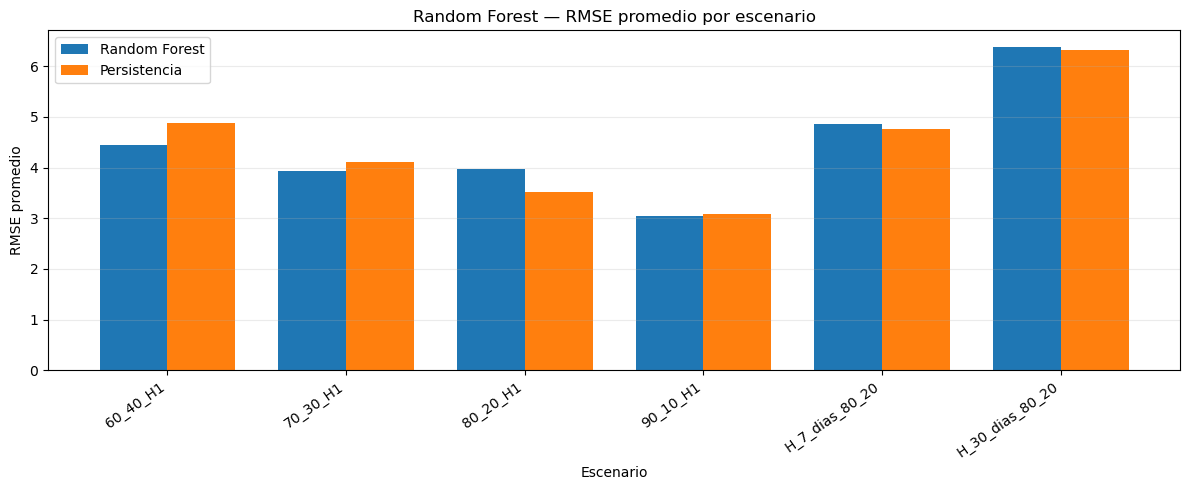

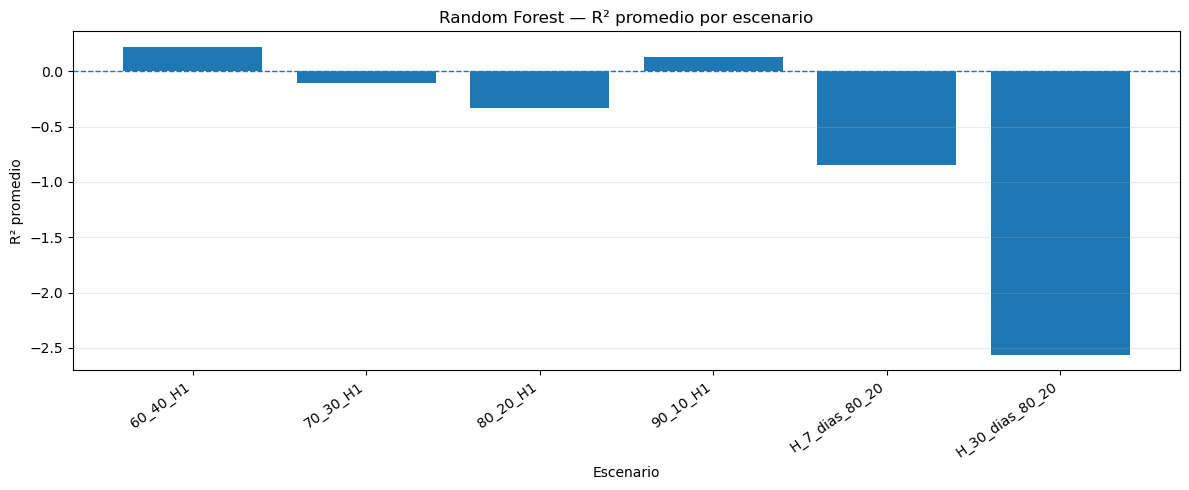

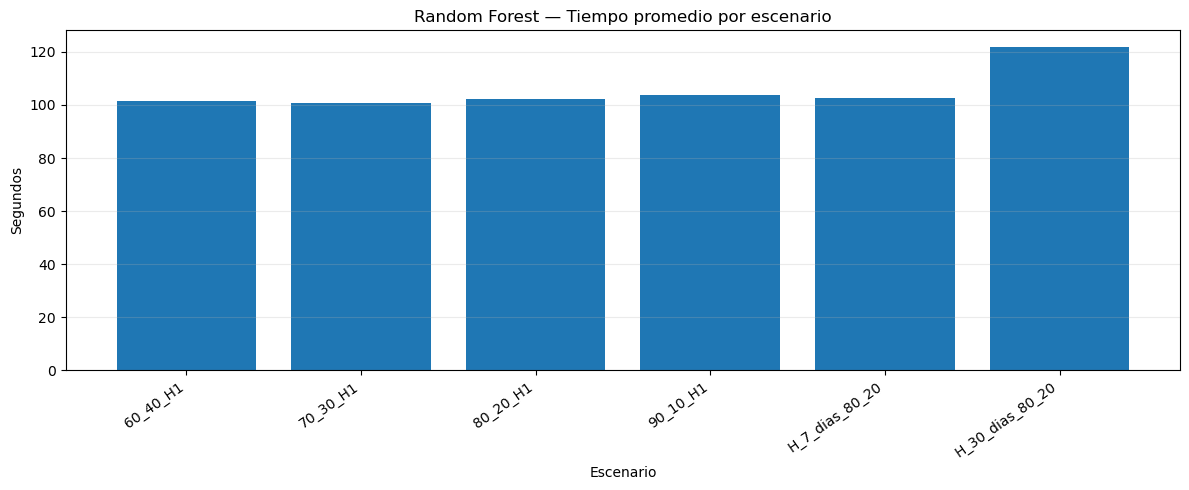

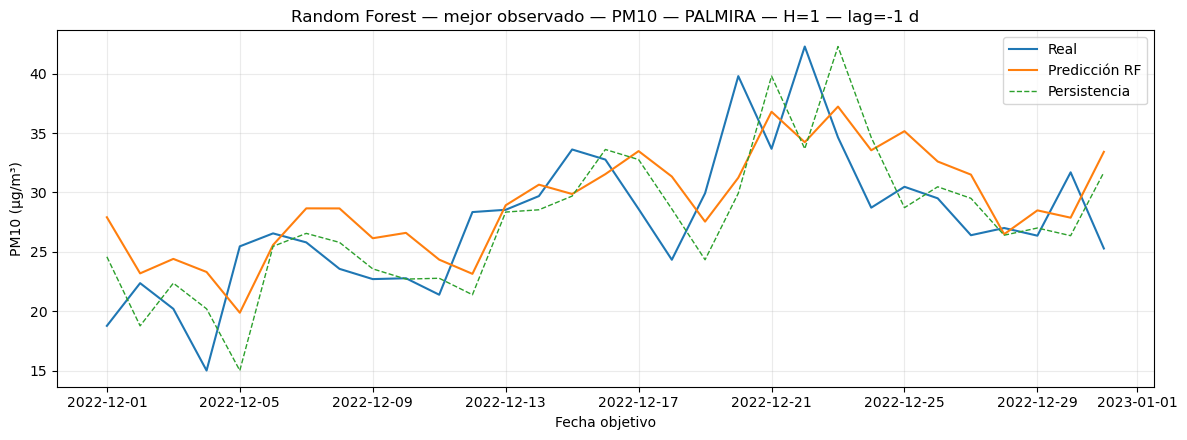

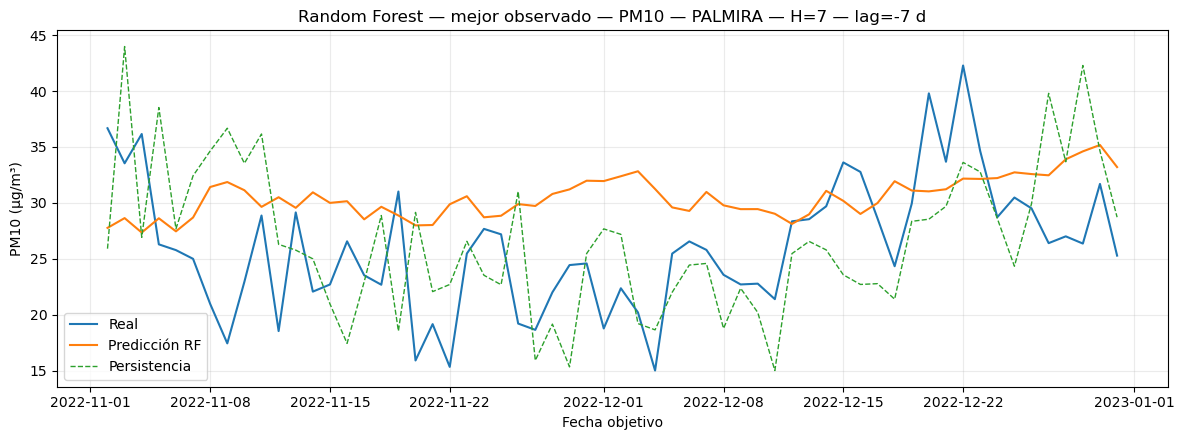

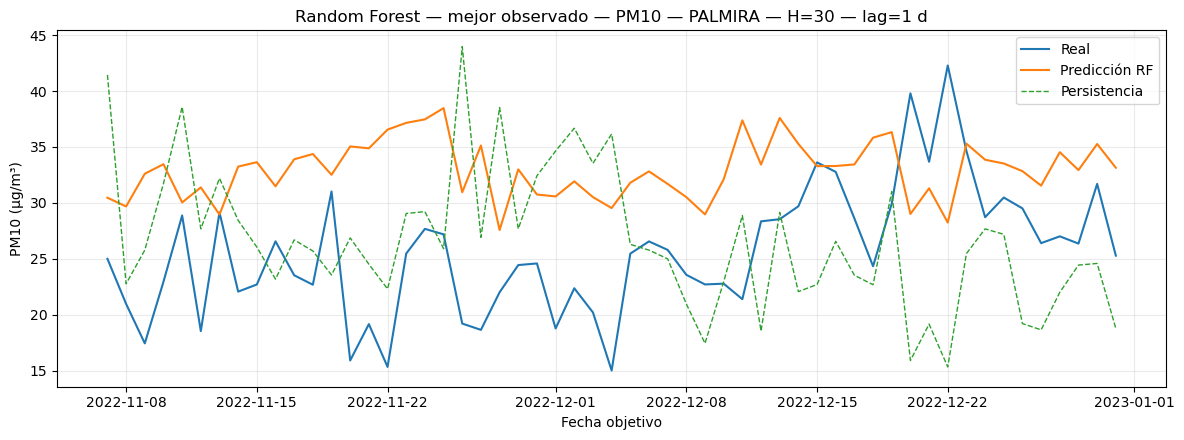

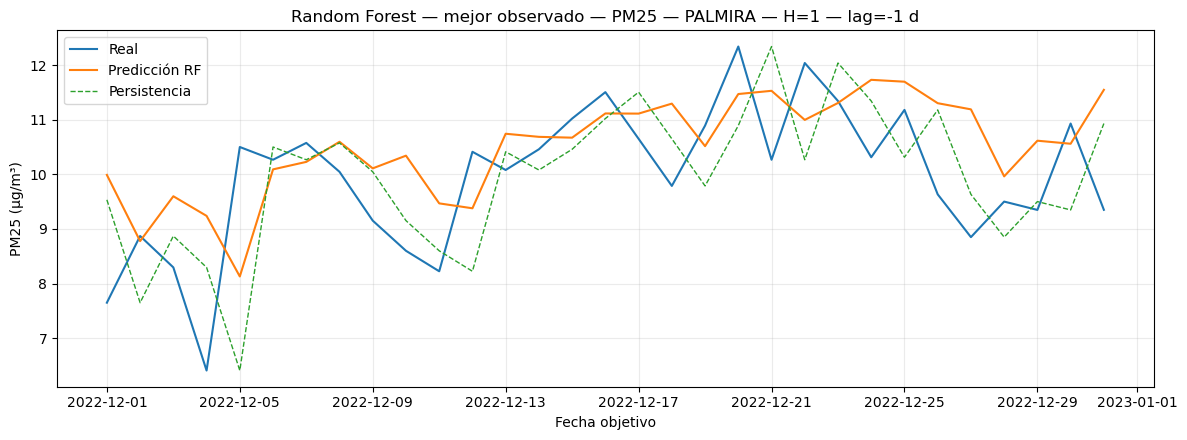

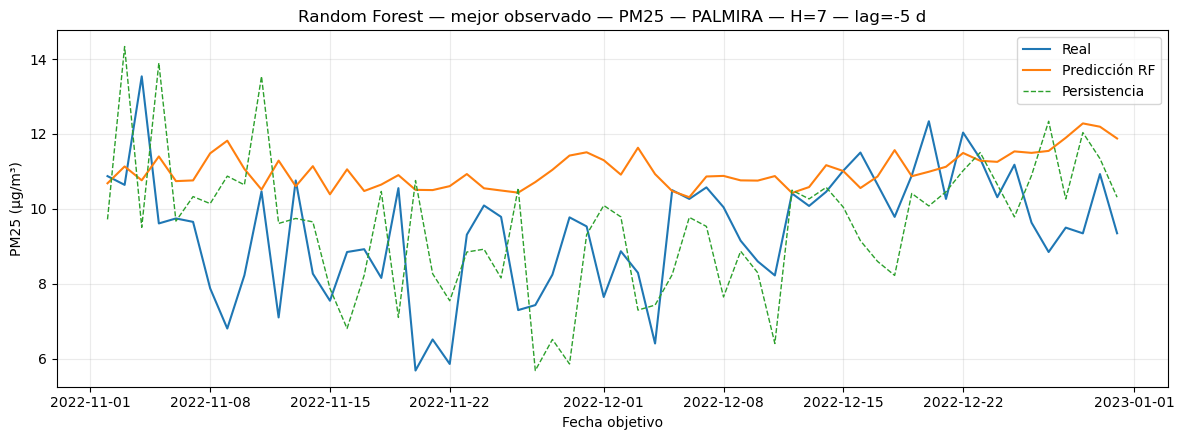

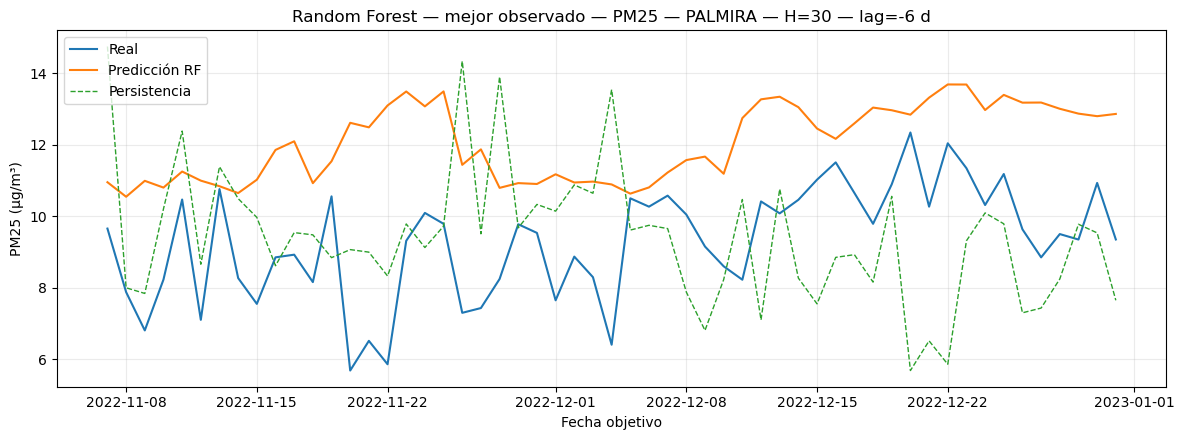

In [37]:

# ============================================================
# 12. TABLAS FINALES ORDENADAS Y GRÁFICAS CONCISAS
# ============================================================

if metricas_rf_df.empty:
    raise ValueError("No se generaron resultados de Random Forest. Revisa la disponibilidad de datos.")

metricas_prueba_rf_df = (
    metricas_rf_df[metricas_rf_df["Etapa"] == "Prueba"]
    .sort_values(["Variable", "Estacion", "Orden_escenario"])
    .reset_index(drop=True)
)

tiempos_rf_df = (
    tiempos_rf_df
    .sort_values(["Variable", "Estacion", "Orden_escenario"])
    .reset_index(drop=True)
)

# Tabla compacta principal de tesis.
columnas_tabla_tesis = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario",
    "Horizonte_dias", "Train_nominal_%", "Train_efectivo_%",
    "Test_efectivo_%", "Gap_purga_dias", "N_registros",
    "MAE", "RMSE", "R2", "sMAPE_%", "WAPE_%", "Sesgo_ME",
    "Lag_optimo_dias", "Lag_abs_dias", "Correlacion_lag0", "Correlacion_max_desfase",
    "RMSE_persistencia", "Mejora_RMSE_vs_persistencia_%"
]
tabla_metricas_tesis_rf = metricas_prueba_rf_df[
    [c for c in columnas_tabla_tesis if c in metricas_prueba_rf_df.columns]
].copy()

columnas_tiempo_tesis = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario",
    "Horizonte_dias", "Train_nominal_%", "Train_efectivo_%",
    "Test_efectivo_%", "Gap_purga_dias", "N_train", "N_test", "N_features",
    "Tipo_modelo_RF", "Hiperparametros_seleccionados", "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Lag_optimo_CV_mediana",
    "Correlacion_lag0_CV_mejor", "Score_CV_alineado", "N_folds_CV",
    "Tiempo_validacion_CV_s", "Tiempo_entrenamiento_final_s",
    "Tiempo_prediccion_s", "Tiempo_total_escenario_s",
    "Tiempo_total_escenario_min"
]
tabla_tiempos_tesis_rf = tiempos_rf_df[
    [c for c in columnas_tiempo_tesis if c in tiempos_rf_df.columns]
].copy()

display(Markdown("## Tabla final de métricas — Random Forest"))
display(tabla_metricas_tesis_rf.round(4))

display(Markdown("## Tabla final de tiempos, configuración e hiperparámetros — Random Forest"))
display(tabla_tiempos_tesis_rf.round(4))

# ------------------------------------------------------------
# Selección automática para visualización, separada por horizonte
# ------------------------------------------------------------
# IMPORTANTE: los hiperparámetros ya fueron elegidos únicamente mediante CV temporal.
# Este score usa la prueba SOLO para resumir cuál resultado observado se visualiza mejor;
# no reentrena ni altera la predicción.

def _score_diagnostico_prueba_rf(grupo):
    g = grupo.copy()
    g["_rmse_n"] = _minmax_seguro_rf(g["RMSE"], True)
    g["_mae_n"] = _minmax_seguro_rf(g["MAE"], True)
    g["_lag_n"] = _minmax_seguro_rf(g["Lag_abs_dias"], True)
    g["_r2_n"] = _minmax_seguro_rf(g["R2"], False)
    g["Score_diagnostico_prueba"] = (
        0.50 * g["_rmse_n"] +
        0.15 * g["_mae_n"] +
        0.25 * g["_lag_n"] +
        0.10 * g["_r2_n"]
    )
    return g.drop(columns=["_rmse_n", "_mae_n", "_lag_n", "_r2_n"])

metricas_prueba_rf_df = (
    metricas_prueba_rf_df
    .groupby(["Variable", "Estacion", "Horizonte_dias"], group_keys=False)
    .apply(_score_diagnostico_prueba_rf)
    .reset_index(drop=True)
)

mejor_rf = (
    metricas_prueba_rf_df
    .sort_values(
        ["Variable", "Estacion", "Horizonte_dias", "Score_diagnostico_prueba", "RMSE", "Lag_abs_dias", "R2"],
        ascending=[True, True, True, True, True, True, False]
    )
    .groupby(["Variable", "Estacion", "Horizonte_dias"], as_index=False)
    .first()
)

display(Markdown("## Mejor resultado observado por contaminante, estación y horizonte"))
display(mejor_rf[[
    "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
    "RMSE", "MAE", "R2", "Lag_optimo_dias", "Correlacion_lag0",
    "Score_diagnostico_prueba", "RMSE_persistencia", "Mejora_RMSE_vs_persistencia_%"
]].round(4))

# Resumen por escenario para las figuras.
resumen_escenarios_rf = (
    metricas_prueba_rf_df
    .groupby(["Orden_escenario", "Tipo_evaluacion", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        RMSE_promedio=("RMSE", "mean"),
        RMSE_persistencia_promedio=("RMSE_persistencia", "mean"),
        R2_promedio=("R2", "mean"),
        Skill_RMSE_promedio=("Mejora_RMSE_vs_persistencia_%", "mean"),
        N_resultados=("RMSE", "count"),
    )
    .sort_values("Orden_escenario")
)

tiempo_escenarios_rf = (
    tiempos_rf_df
    .groupby(["Orden_escenario", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        Tiempo_total_promedio_s=("Tiempo_total_escenario_s", "mean"),
        Tiempo_total_acumulado_s=("Tiempo_total_escenario_s", "sum"),
    )
    .sort_values("Orden_escenario")
)

# Figura 1: RMSE modelo vs persistencia.
x = np.arange(len(resumen_escenarios_rf))
w = 0.38
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, resumen_escenarios_rf["RMSE_promedio"], width=w, label="Random Forest")
plt.bar(x + w/2, resumen_escenarios_rf["RMSE_persistencia_promedio"], width=w, label="Persistencia")
plt.xticks(x, resumen_escenarios_rf["Escenario"], rotation=35, ha="right")
plt.ylabel("RMSE promedio")
plt.xlabel("Escenario")
plt.title("Random Forest — RMSE promedio por escenario")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_RF / "RF_resumen_RMSE_vs_persistencia.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Figura 2: R² promedio.
plt.figure(figsize=(12, 5))
plt.bar(resumen_escenarios_rf["Escenario"], resumen_escenarios_rf["R2_promedio"])
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(rotation=35, ha="right")
plt.ylabel("R² promedio")
plt.xlabel("Escenario")
plt.title("Random Forest — R² promedio por escenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_RF / "RF_resumen_R2.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Figura 3: tiempo promedio de ejecución.
plt.figure(figsize=(12, 5))
plt.bar(tiempo_escenarios_rf["Escenario"], tiempo_escenarios_rf["Tiempo_total_promedio_s"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Segundos")
plt.xlabel("Escenario")
plt.title("Random Forest — Tiempo promedio por escenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_RF / "RF_resumen_tiempos.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Detalle real vs predicción: solo del mejor escenario de cada estación/variable.
for _, fila in mejor_rf.iterrows():
    sub = predicciones_rf_df[
        (predicciones_rf_df["Variable"] == fila["Variable"]) &
        (predicciones_rf_df["Estacion"] == fila["Estacion"]) &
        (predicciones_rf_df["Escenario"] == fila["Escenario"])
    ].sort_values("Fecha_objetivo")

    if sub.empty:
        continue

    plt.figure(figsize=(12, 4.5))
    plt.plot(sub["Fecha_objetivo"], sub["Real"], label="Real", linewidth=1.5)
    plt.plot(sub["Fecha_objetivo"], sub["Prediccion"], label="Predicción RF", linewidth=1.5)
    plt.plot(sub["Fecha_objetivo"], sub["Persistencia"], linestyle="--", label="Persistencia", linewidth=1.0)
    plt.ylabel(f"{fila['Variable']} (µg/m³)")
    plt.xlabel("Fecha objetivo")
    plt.title(f"Random Forest — mejor observado — {fila['Variable']} — {fila['Estacion']} — H={int(fila['Horizonte_dias'])} — lag={fila['Lag_optimo_dias']:.0f} d")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    nombre = nombre_seguro_rf(f"{fila['Variable']}_{fila['Estacion']}_{fila['Escenario']}")
    plt.savefig(GRAFICAS_RF / f"RF_mejor_{nombre}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()


## Diagnóstico temporal de residuales

Para complementar las métricas agregadas se analiza, fecha a fecha, el **residual de predicción**:

\[
e_t = y_t - \hat{y}_t
\]

- **Residual positivo**: el modelo **subestima** la concentración observada.
- **Residual negativo**: el modelo **sobreestima** la concentración observada.
- **Residual cercano a cero**: la predicción se aproxima al valor observado.

Se guarda la serie residual de **todos los escenarios** y, para mantener el notebook claro y conciso, se muestran en pantalla los residuales correspondientes al **mejor escenario** de cada estación y contaminante. También se calcula una tabla de diagnóstico con media, mediana, desviación estándar, percentil 95 del error absoluto y autocorrelación de rezago 1. Un buen modelo debería presentar residuales centrados alrededor de cero y sin una estructura temporal sistemática evidente.


## Diagnóstico de residuales — Random Forest

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,N_residuales,Residual_medio,Residual_mediana,Residual_desv_std,MAE_desde_residual,P95_error_absoluto,Max_error_absoluto,Autocorr_residual_lag1
0,Random Forest,PM10,PALMIRA,Particion porcentual,60_40_H1,1,122,-0.9703,-1.8933,6.5405,5.2504,12.9621,20.2997,-0.1037
1,Random Forest,PM10,PALMIRA,Particion porcentual,70_30_H1,1,92,-1.9764,-2.9402,5.5370,4.8459,10.8796,15.1946,-0.2027
2,Random Forest,PM10,PALMIRA,Particion porcentual,80_20_H1,1,61,-2.6836,-3.2927,5.2898,4.9750,10.0319,15.1073,-0.0671
3,Random Forest,PM10,PALMIRA,Particion porcentual,90_10_H1,1,31,-1.5321,-2.8664,4.6302,4.1185,8.4275,9.1457,-0.0439
4,Random Forest,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,60,-4.3749,-5.0673,6.0491,6.2431,13.2479,16.2402,0.5277
5,Random Forest,PM10,PALMIRA,Horizonte fijo,H_30_dias_80_20,30,55,-7.3323,-6.9476,6.3038,8.3412,16.1464,21.2259,0.3922
6,Random Forest,PM25,PALMIRA,Particion porcentual,60_40_H1,1,122,-0.6173,-0.9565,2.2116,1.8064,4.5418,7.1242,-0.1029
7,Random Forest,PM25,PALMIRA,Particion porcentual,70_30_H1,1,92,-1.0108,-1.0895,1.7491,1.6589,3.7415,5.5731,-0.1809
8,Random Forest,PM25,PALMIRA,Particion porcentual,80_20_H1,1,61,-1.3391,-1.3212,1.5432,1.6774,3.7258,5.6342,-0.2334
9,Random Forest,PM25,PALMIRA,Particion porcentual,90_10_H1,1,31,-0.5644,-0.5162,1.1844,1.0453,2.3545,2.8306,-0.1147


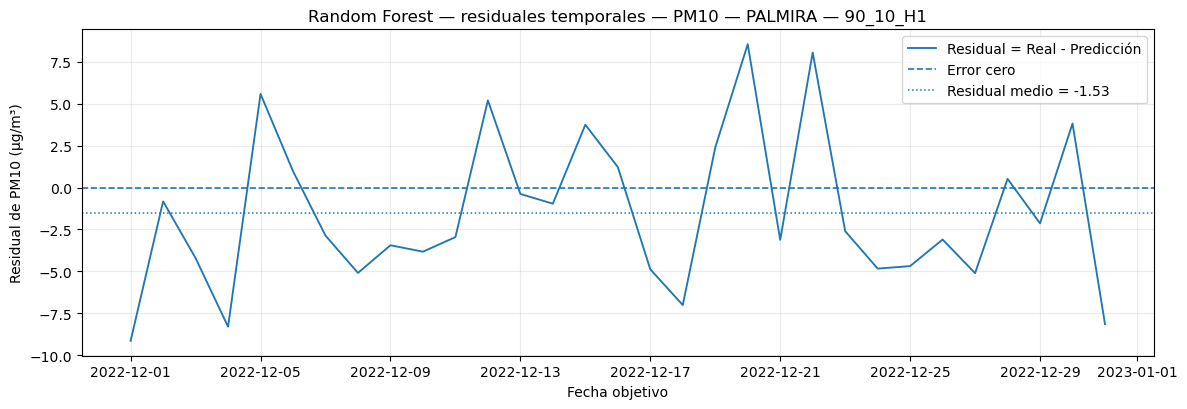

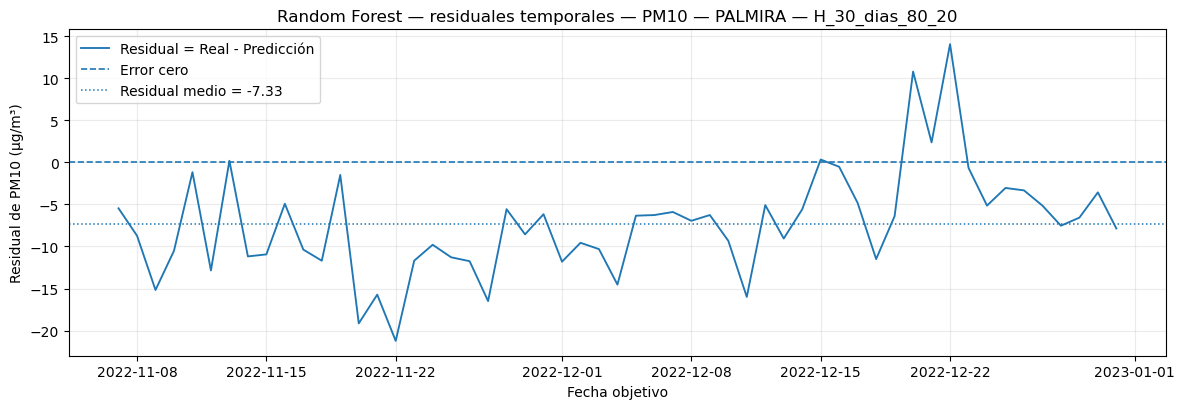

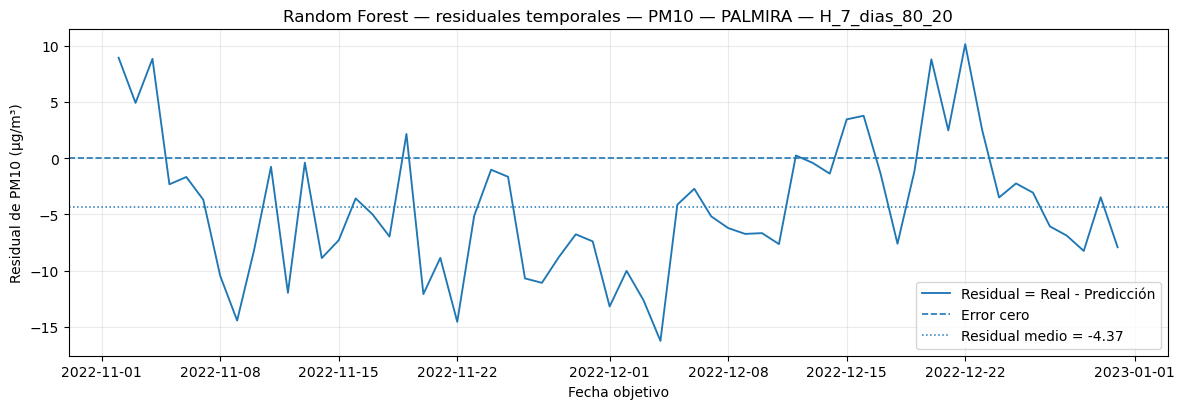

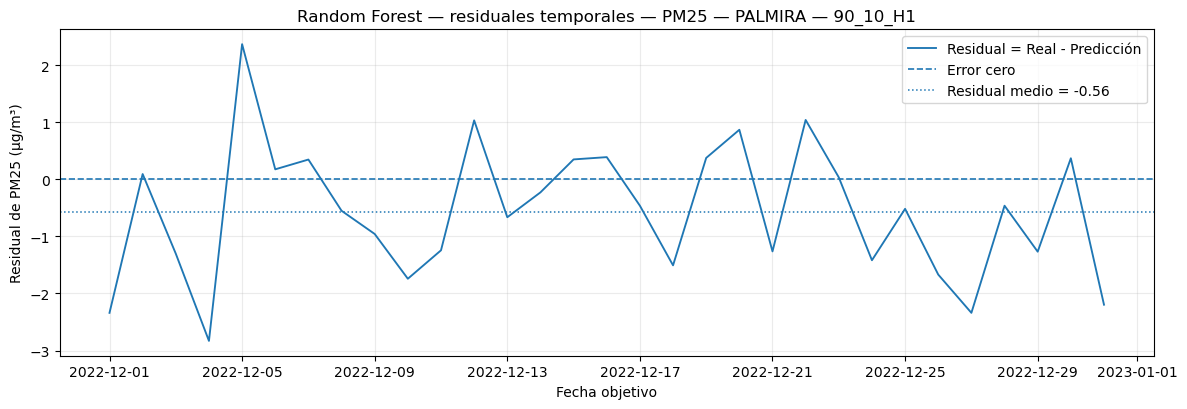

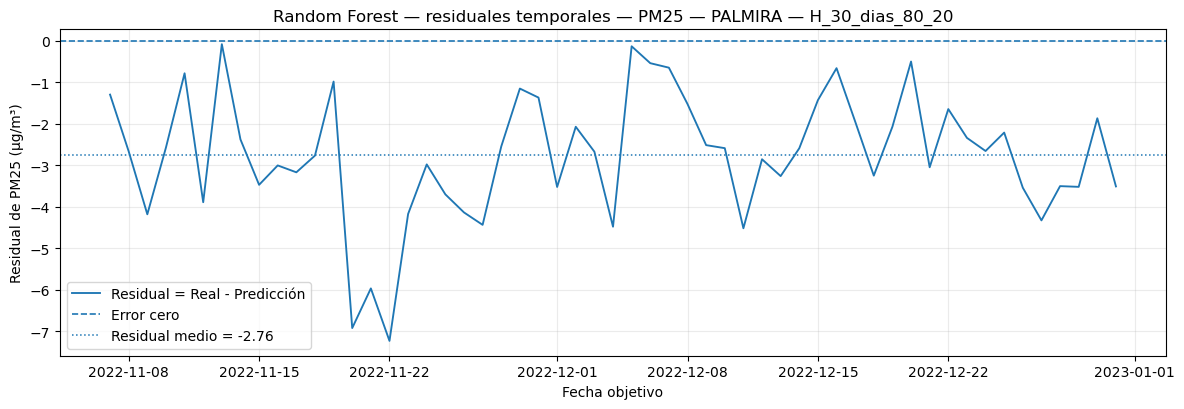

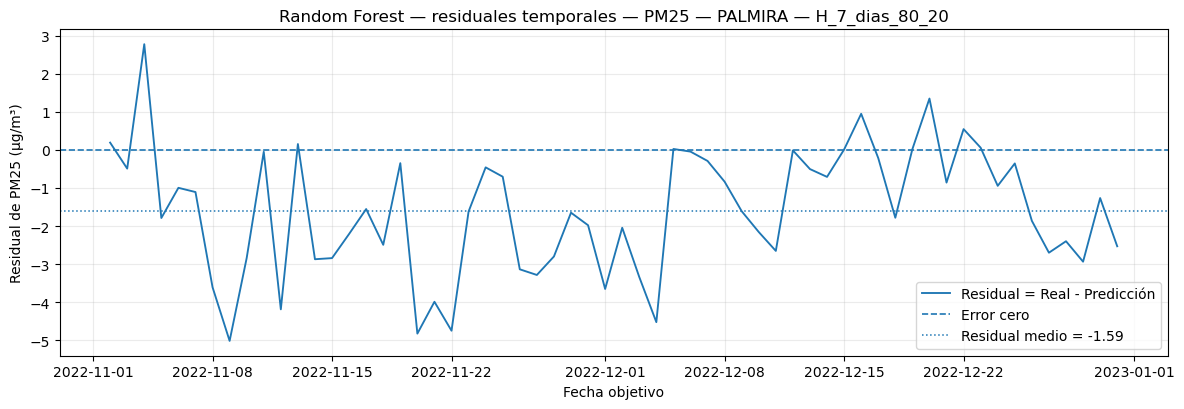

Resumen de residuales guardado en: C:\Users\santi\Prediccion_Cali_3_Version\salidas_RF_TESIS_PROTOCOLO_TEMPORAL\tablas\RF_resumen_residuales.csv
Gráficas residuales de todos los escenarios en: C:\Users\santi\Prediccion_Cali_3_Version\salidas_RF_TESIS_PROTOCOLO_TEMPORAL\graficas\residuales_todos_escenarios


In [38]:
# ============================================================
# DIAGNÓSTICO TEMPORAL DE RESIDUALES: REAL - PREDICCIÓN
# ============================================================

if predicciones_rf_df.empty:
    raise ValueError("No hay predicciones disponibles para calcular residuales.")

# Residual con convención explícita para la tesis: observado menos predicho.
predicciones_rf_df = predicciones_rf_df.copy()
predicciones_rf_df["Residual"] = predicciones_rf_df["Real"] - predicciones_rf_df["Prediccion"]
predicciones_rf_df["Error_absoluto"] = predicciones_rf_df["Residual"].abs()
if "Persistencia" in predicciones_rf_df.columns:
    predicciones_rf_df["Residual_persistencia"] = predicciones_rf_df["Real"] - predicciones_rf_df["Persistencia"]

# Resumen de diagnóstico residual por escenario.
def _autocorr_lag1_residual(serie):
    serie = pd.Series(serie).dropna()
    return serie.autocorr(lag=1) if len(serie) >= 3 else np.nan

resumen_residuales_rf = (
    predicciones_rf_df
    .groupby(["Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        N_residuales=("Residual", "count"),
        Residual_medio=("Residual", "mean"),
        Residual_mediana=("Residual", "median"),
        Residual_desv_std=("Residual", "std"),
        MAE_desde_residual=("Error_absoluto", "mean"),
        P95_error_absoluto=("Error_absoluto", lambda x: x.quantile(0.95)),
        Max_error_absoluto=("Error_absoluto", "max"),
        Autocorr_residual_lag1=("Residual", _autocorr_lag1_residual),
    )
    .sort_values(["Variable", "Estacion", "Horizonte_dias", "Escenario"])
    .reset_index(drop=True)
)

display(Markdown("## Diagnóstico de residuales — Random Forest"))
display(resumen_residuales_rf.round(4))

# Carpeta específica: se guardan todos los escenarios aunque solo se muestren los mejores.
GRAFICAS_RESIDUALES_RF = GRAFICAS_RF / "residuales_todos_escenarios"
GRAFICAS_RESIDUALES_RF.mkdir(parents=True, exist_ok=True)

# Identificar mejores escenarios para mostrarlos en pantalla sin saturar el notebook.
_mejores_claves_rf = set(
    zip(mejor_rf["Variable"], mejor_rf["Estacion"], mejor_rf["Escenario"])
)

for (variable, estacion, escenario, horizonte), sub in predicciones_rf_df.groupby(
    ["Variable", "Estacion", "Escenario", "Horizonte_dias"]
):
    sub = sub.sort_values("Fecha_objetivo").copy()
    if sub.empty:
        continue

    media_residual = sub["Residual"].mean()

    plt.figure(figsize=(12, 4.2))
    plt.plot(sub["Fecha_objetivo"], sub["Residual"], linewidth=1.35, label="Residual = Real - Predicción")
    plt.axhline(0, linestyle="--", linewidth=1.2, label="Error cero")
    plt.axhline(media_residual, linestyle=":", linewidth=1.1, label=f"Residual medio = {media_residual:.2f}")
    plt.xlabel("Fecha objetivo")
    plt.ylabel(f"Residual de {variable} (µg/m³)")
    plt.title(f"Random Forest — residuales temporales — {variable} — {estacion} — {escenario}")
    plt.legend(loc="best")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    nombre = nombre_seguro_rf(f"{variable}_{estacion}_{escenario}_H{horizonte}")
    plt.savefig(
        GRAFICAS_RESIDUALES_RF / f"RF_residual_{nombre}.png",
        dpi=180,
        bbox_inches="tight"
    )

    # Solo se muestra el mejor escenario por estación/variable; los demás quedan guardados.
    if (variable, estacion, escenario) in _mejores_claves_rf:
        plt.show()
    plt.close()

# Tabla específica de residuales para trazabilidad.
ruta_residuales_rf = TABLAS_RF / "RF_resumen_residuales.csv"
resumen_residuales_rf.to_csv(ruta_residuales_rf, index=False, encoding="utf-8-sig")
print("Resumen de residuales guardado en:", ruta_residuales_rf.resolve())
print("Gráficas residuales de todos los escenarios en:", GRAFICAS_RESIDUALES_RF.resolve())


## Figuras completas por intervalo: entrenamiento, predicción y residual

Para cada escenario se presenta una figura con dos paneles sincronizados en el tiempo:

1. **Panel superior:** serie observada usada como entrenamiento, serie observada de prueba y predicción del modelo. La línea vertical marca el inicio del conjunto de prueba. Cuando existe una purga temporal, se identifica visualmente entre el final del entrenamiento y el inicio de prueba.
2. **Panel inferior:** residual fuera de muestra, definido como \(e_t = y_t - \hat{y}_t\). Un residual positivo indica subestimación y uno negativo indica sobreestimación.

El residual se calcula sobre **prueba**, porque es donde se evalúa la capacidad predictiva fuera de muestra. No se desplaza la predicción para mejorar artificialmente su coincidencia visual.


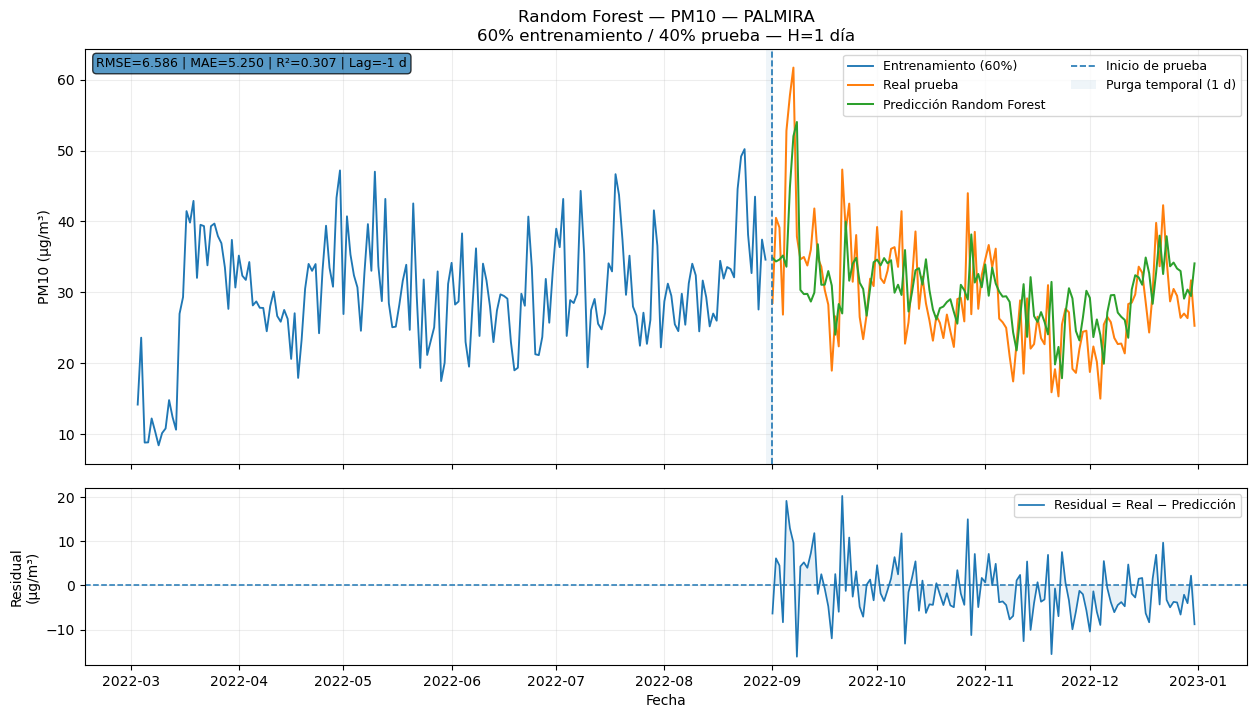

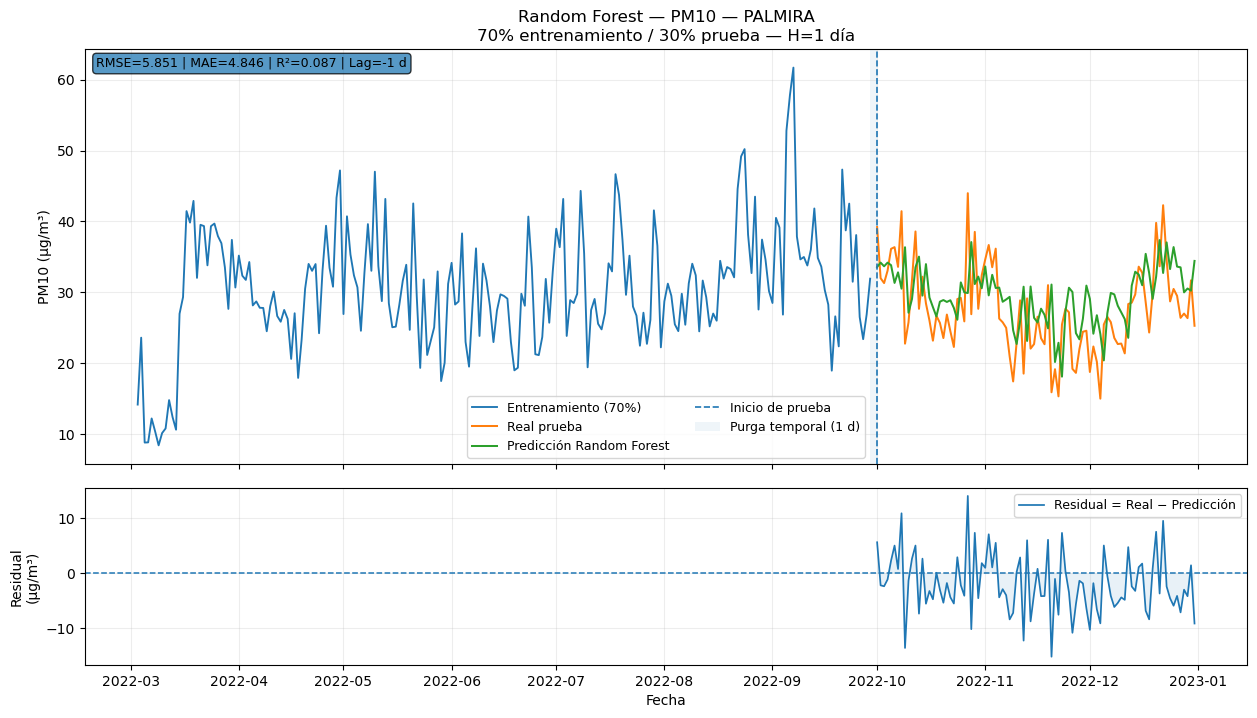

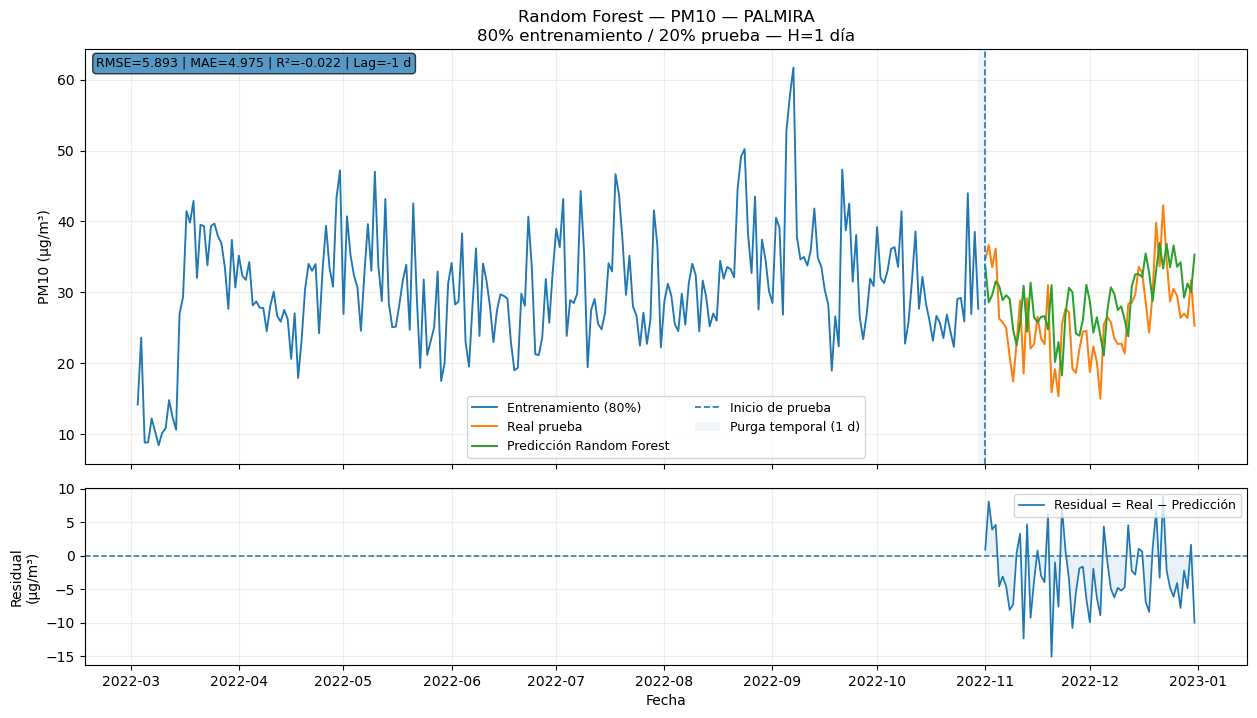

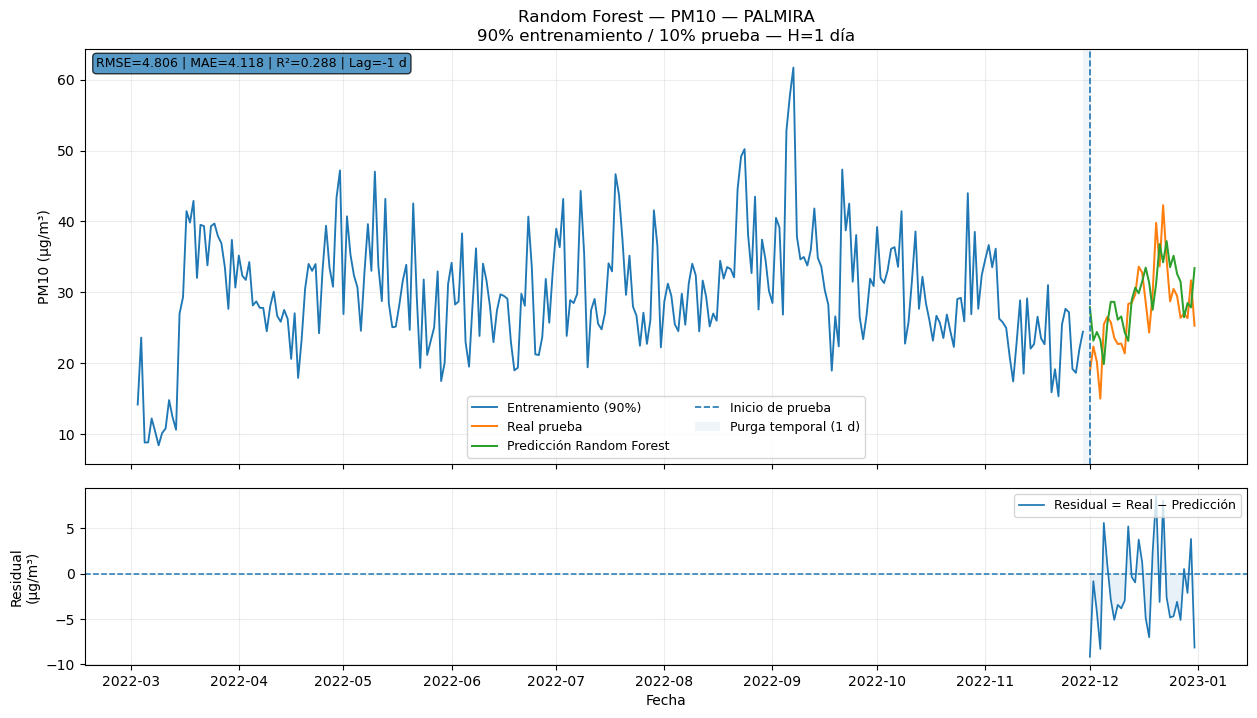

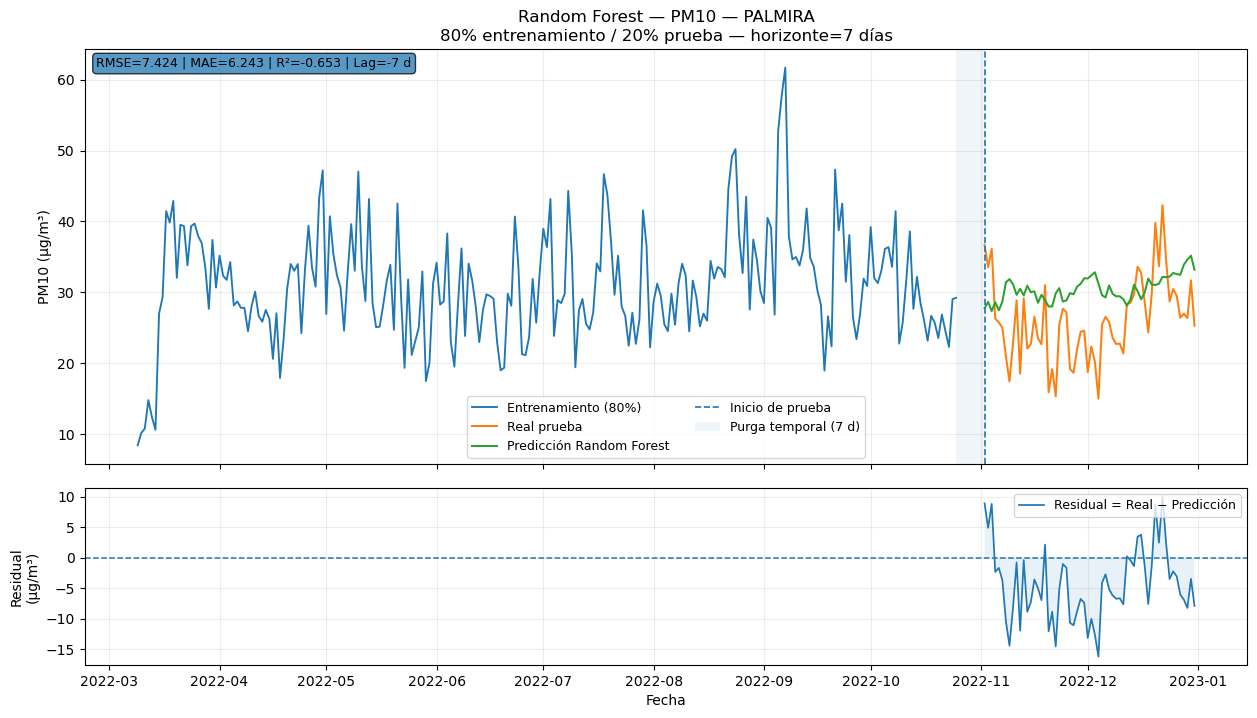

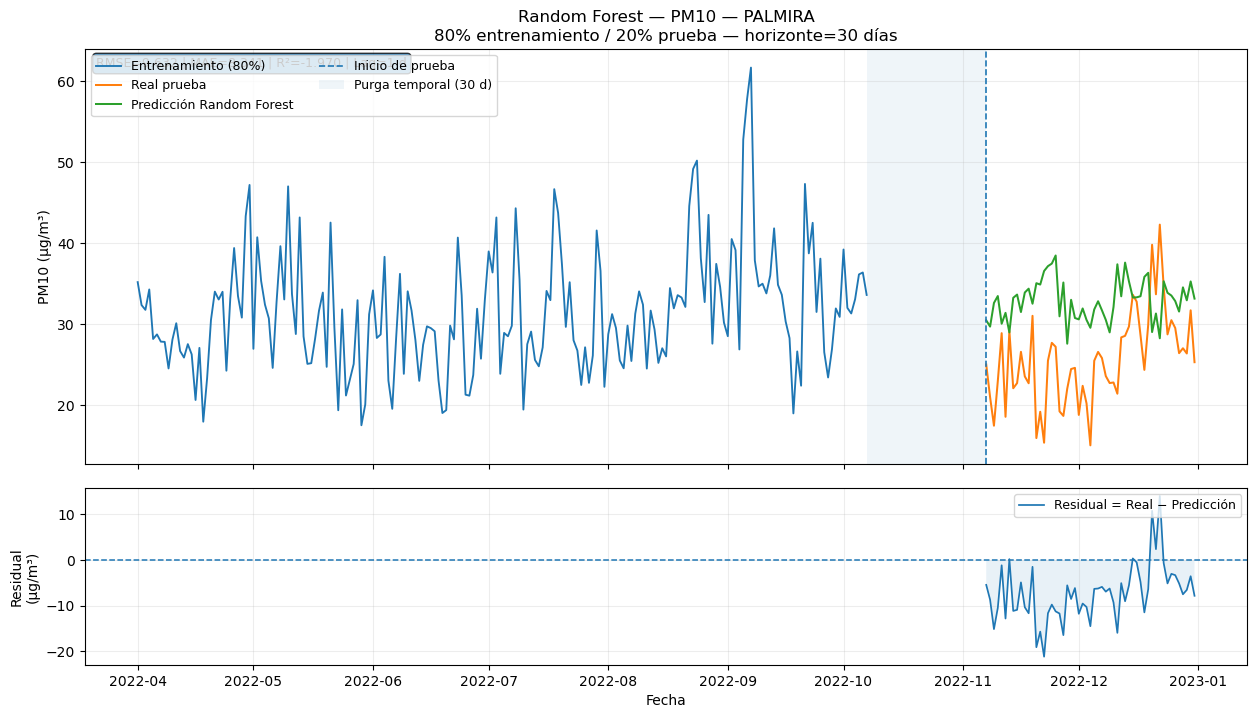

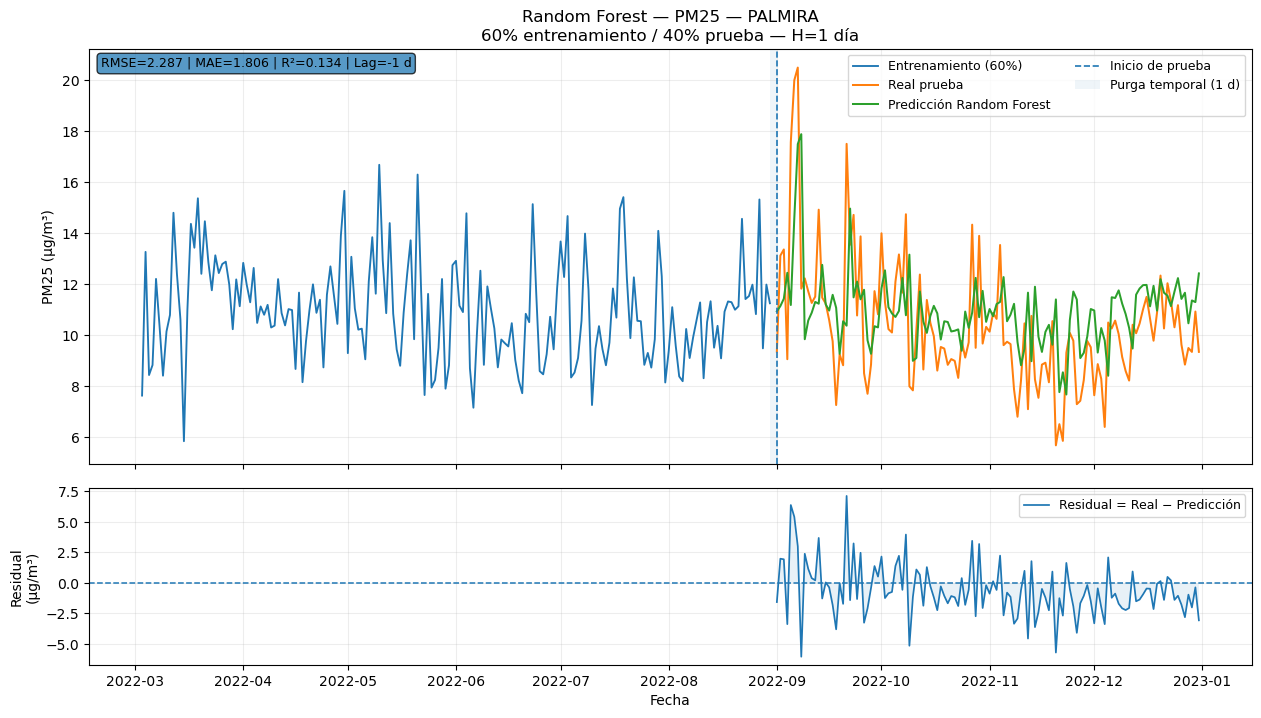

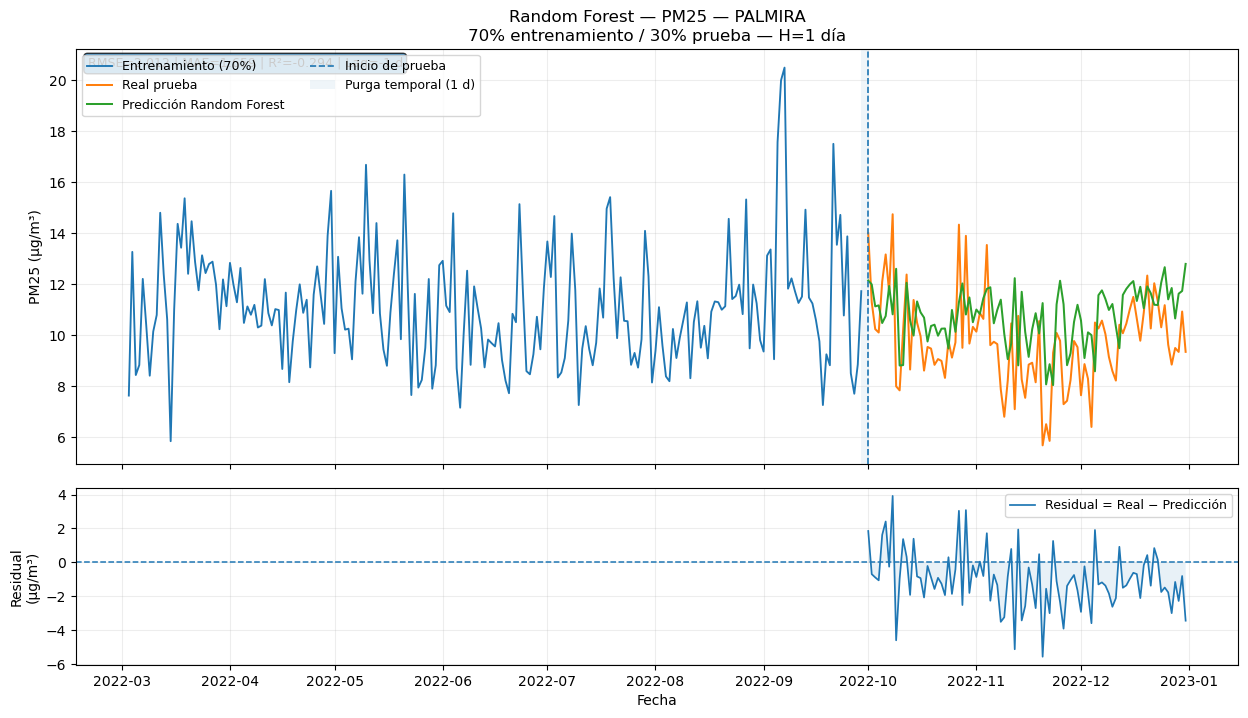

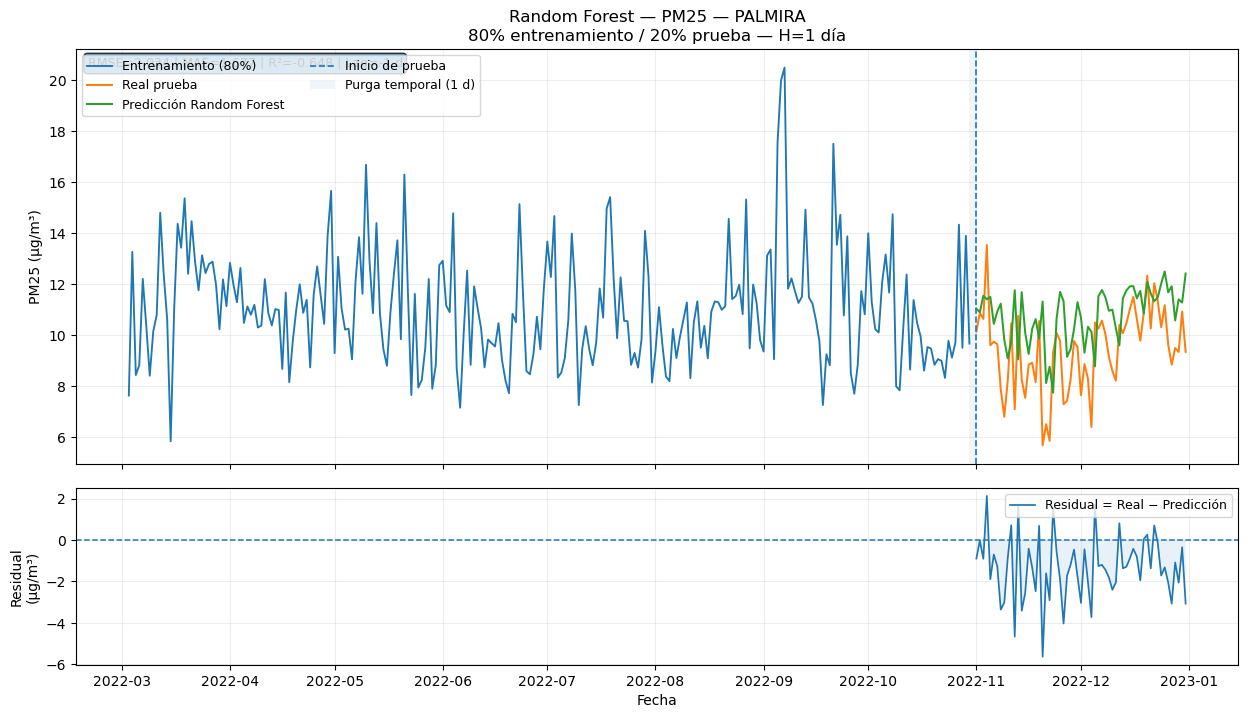

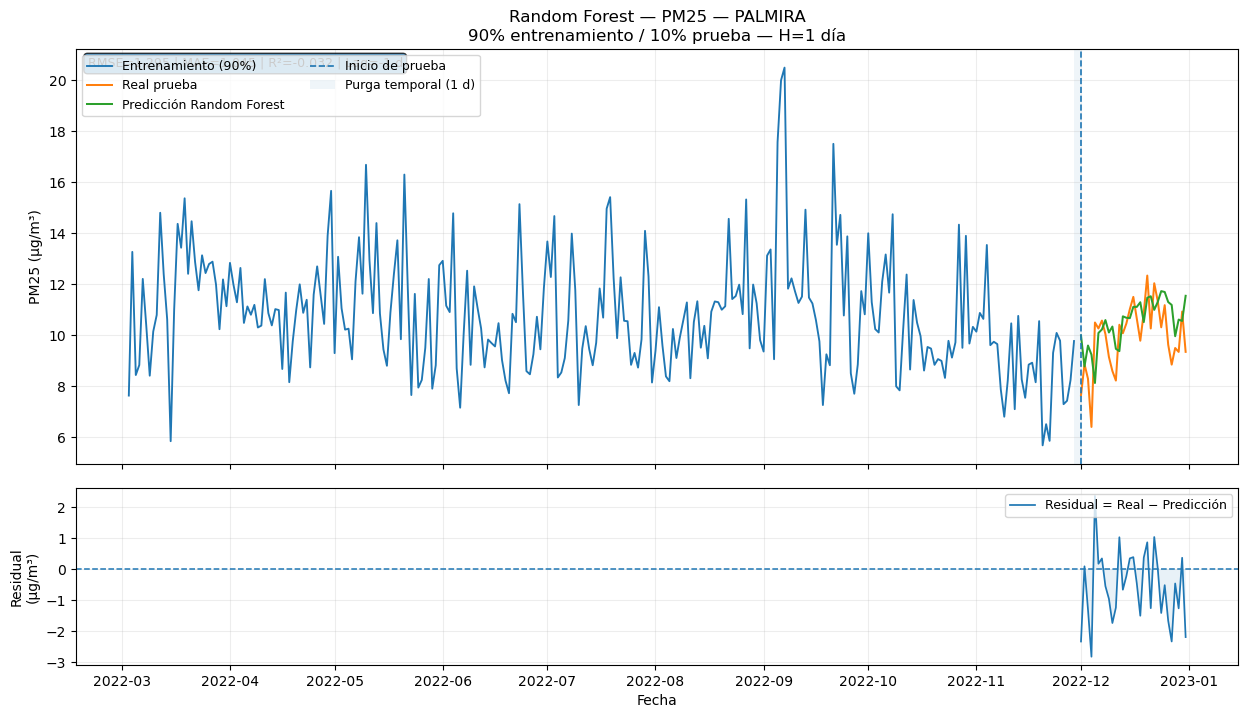

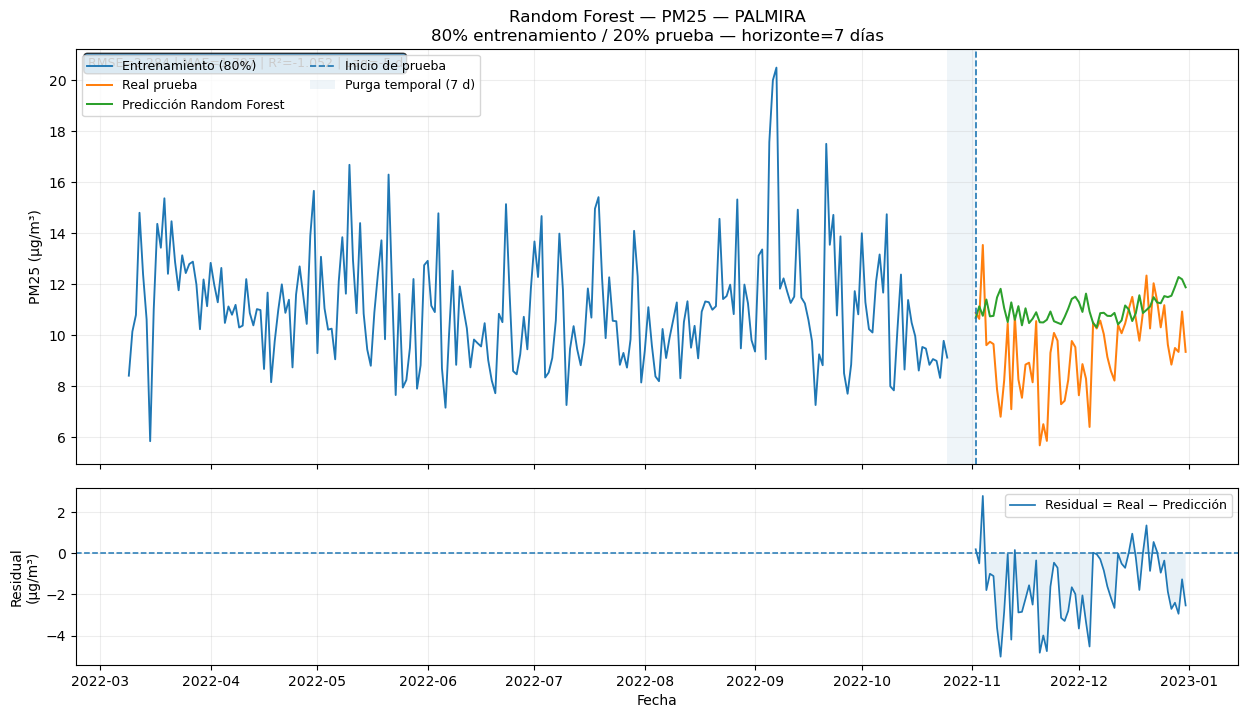

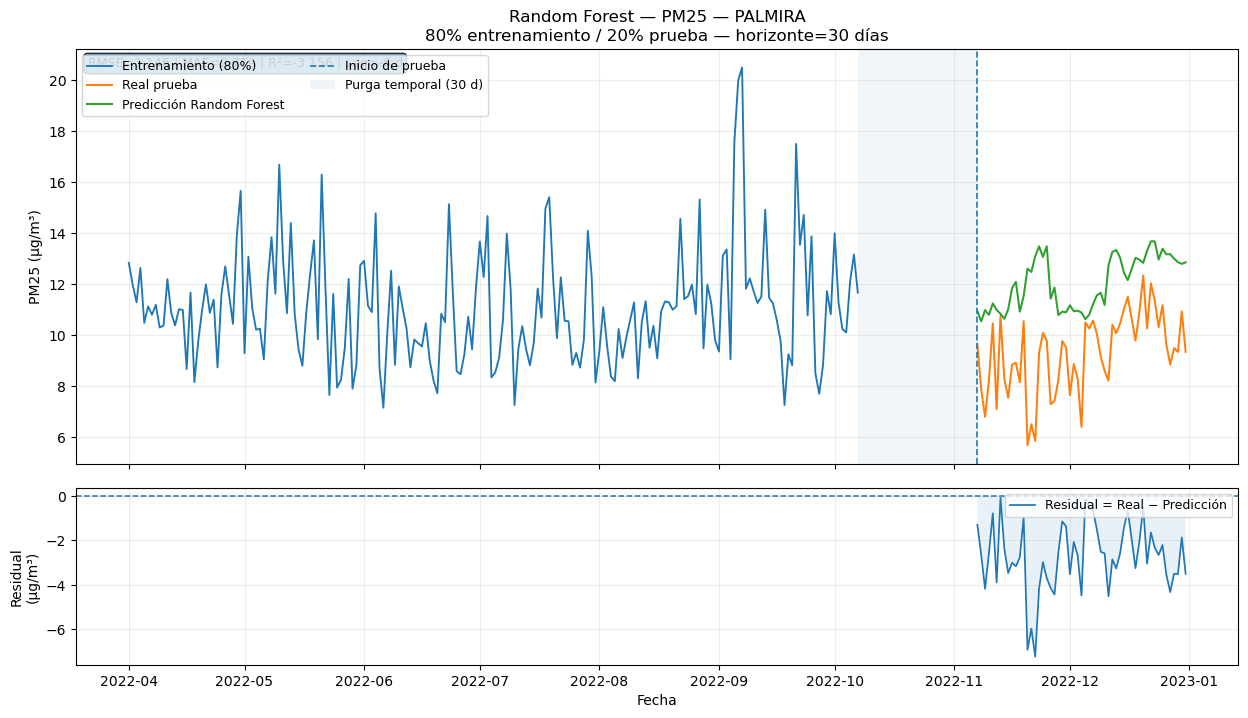

Figuras entrenamiento/prueba + residual generadas: 12


In [39]:
# V3_GRAFICAS_TRAIN_TEST_RESIDUAL
# ============================================================
# FIGURAS POR CADA INTERVALO: ENTRENAMIENTO + PRUEBA/PREDICCIÓN
# Y RESIDUAL (REAL - PREDICCIÓN) EN PANEL INFERIOR
# ============================================================

# Asegurar tipos temporales y residual.
predicciones_rf_df = predicciones_rf_df.copy()
predicciones_rf_df["Fecha_objetivo"] = pd.to_datetime(predicciones_rf_df["Fecha_objetivo"], errors="coerce")
predicciones_rf_df["Residual"] = predicciones_rf_df["Real"] - predicciones_rf_df["Prediccion"]

_base_graf_rf = base.copy()
_base_graf_rf["Fecha inicial"] = pd.to_datetime(_base_graf_rf["Fecha inicial"], errors="coerce")


def _etiqueta_intervalo_rf(tipo, train_nominal, horizonte):
    train_nominal = float(train_nominal)
    test_nominal = 100.0 - train_nominal
    if str(tipo).lower().startswith("particion"):
        return f"{train_nominal:.0f}% entrenamiento / {test_nominal:.0f}% prueba — H=1 día"
    return f"{train_nominal:.0f}% entrenamiento / {test_nominal:.0f}% prueba — horizonte={int(horizonte)} días"


def _graficar_intervalo_rf(fila_cfg):
    variable = fila_cfg["Variable"]
    estacion = fila_cfg["Estacion"]
    escenario = fila_cfg["Escenario"]
    tipo_eval = fila_cfg["Tipo_evaluacion"]
    horizonte = int(fila_cfg["Horizonte_dias"])

    sub = predicciones_rf_df[
        (predicciones_rf_df["Variable"] == variable) &
        (predicciones_rf_df["Estacion"] == estacion) &
        (predicciones_rf_df["Escenario"] == escenario)
    ].sort_values("Fecha_objetivo").copy()
    if sub.empty:
        return

    # Configuración temporal registrada para este escenario.
    trow = tiempos_rf_df[
        (tiempos_rf_df["Variable"] == variable) &
        (tiempos_rf_df["Estacion"] == estacion) &
        (tiempos_rf_df["Escenario"] == escenario)
    ]
    if trow.empty:
        train_nominal = 80.0
        gap_dias = horizonte
    else:
        train_nominal = float(trow.iloc[0]["Train_nominal_%"])
        gap_dias = int(trow.iloc[0].get("Gap_purga_dias", horizonte))

    # Fechas exactas del tramo de entrenamiento utilizadas por el protocolo.
    train_info = metricas_rf_df[
        (metricas_rf_df["Variable"] == variable) &
        (metricas_rf_df["Estacion"] == estacion) &
        (metricas_rf_df["Escenario"] == escenario) &
        (metricas_rf_df["Etapa"] == "Entrenamiento")
    ]

    fecha_test_inicio = pd.to_datetime(sub["Fecha_objetivo"].min())
    if not train_info.empty:
        fecha_train_inicio = pd.to_datetime(train_info.iloc[0]["Fecha_inicio"])
        fecha_train_fin = pd.to_datetime(train_info.iloc[0]["Fecha_fin"])
    else:
        fecha_train_inicio = pd.to_datetime(_base_graf_rf["Fecha inicial"].min())
        fecha_train_fin = fecha_test_inicio - pd.Timedelta(days=max(1, gap_dias))

    serie = _base_graf_rf[
        (_base_graf_rf["Estacion"] == estacion)
    ][["Fecha inicial", variable]].copy()
    serie[variable] = pd.to_numeric(serie[variable], errors="coerce")
    serie = serie.dropna(subset=["Fecha inicial", variable]).sort_values("Fecha inicial")

    train_obs = serie[
        (serie["Fecha inicial"] >= fecha_train_inicio) &
        (serie["Fecha inicial"] <= fecha_train_fin)
    ].copy()

    residual = sub["Residual"].astype(float)
    rmse = float(np.sqrt(np.nanmean(np.square(residual)))) if residual.notna().any() else np.nan
    mae = float(np.nanmean(np.abs(residual))) if residual.notna().any() else np.nan
    r2_row = metricas_rf_df[
        (metricas_rf_df["Variable"] == variable) &
        (metricas_rf_df["Estacion"] == estacion) &
        (metricas_rf_df["Escenario"] == escenario) &
        (metricas_rf_df["Etapa"] == "Prueba")
    ]
    r2 = float(r2_row.iloc[0]["R2"]) if (not r2_row.empty and "R2" in r2_row.columns) else np.nan
    lag = float(r2_row.iloc[0]["Lag_optimo_dias"]) if (not r2_row.empty and "Lag_optimo_dias" in r2_row.columns) else np.nan

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(15, 8), sharex=True,
        gridspec_kw={"height_ratios": [2.35, 1.0], "hspace": 0.08}
    )

    # Panel superior: mismo concepto visual de la figura solicitada.
    ax1.plot(train_obs["Fecha inicial"], train_obs[variable],
             label=f"Entrenamiento ({train_nominal:.0f}%)", linewidth=1.35)
    ax1.plot(sub["Fecha_objetivo"], sub["Real"],
             label="Real prueba", linewidth=1.45)
    ax1.plot(sub["Fecha_objetivo"], sub["Prediccion"],
             label="Predicción Random Forest", linewidth=1.45)
    ax1.axvline(fecha_test_inicio, linestyle="--", linewidth=1.2, label="Inicio de prueba")

    # Mostrar la purga temporal sin confundirla con datos de prueba.
    if pd.notna(fecha_train_fin) and fecha_train_fin < fecha_test_inicio:
        ax1.axvspan(fecha_train_fin, fecha_test_inicio, alpha=0.07,
                    label=f"Purga temporal ({gap_dias} d)")

    etiqueta = _etiqueta_intervalo_rf(tipo_eval, train_nominal, horizonte)
    ax1.set_title(f"Random Forest — {variable} — {estacion}\n{etiqueta}")
    ax1.set_ylabel(f"{variable} (µg/m³)")
    ax1.grid(alpha=0.22)
    ax1.legend(ncol=2, fontsize=9)

    texto_metricas = f"RMSE={rmse:.3f} | MAE={mae:.3f} | R²={r2:.3f}"
    if np.isfinite(lag):
        texto_metricas += f" | Lag={lag:.0f} d"
    ax1.text(0.01, 0.98, texto_metricas, transform=ax1.transAxes,
             va="top", ha="left", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.3", alpha=0.75))

    # Panel inferior: resta Real - Predicción para las mismas fechas de prueba.
    ax2.plot(sub["Fecha_objetivo"], residual, linewidth=1.25, label="Residual = Real − Predicción")
    ax2.axhline(0, linestyle="--", linewidth=1.1)
    ax2.fill_between(sub["Fecha_objetivo"], residual, 0, alpha=0.10)
    ax2.set_ylabel("Residual\n(µg/m³)")
    ax2.set_xlabel("Fecha")
    ax2.grid(alpha=0.22)
    ax2.legend(loc="upper right", fontsize=9)

    fig.tight_layout()
    nombre = nombre_seguro_rf(f"{variable}_{estacion}_{escenario}")
    ruta = GRAFICAS_RF / f"RF_train_test_residual_{nombre}.png"
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Se muestran y guardan TODOS los escenarios: 60/40, 70/30, 80/20, 90/10, H7, H30 y H90.
_cfg_graficas_rf = (
    predicciones_rf_df[["Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"]]
    .drop_duplicates()
    .merge(
        tiempos_rf_df[["Variable", "Estacion", "Escenario", "Orden_escenario"]].drop_duplicates(),
        on=["Variable", "Estacion", "Escenario"], how="left"
    )
    .sort_values(["Variable", "Estacion", "Orden_escenario", "Horizonte_dias"])
)

for _, _fila_cfg in _cfg_graficas_rf.iterrows():
    _graficar_intervalo_rf(_fila_cfg)

print(f"Figuras entrenamiento/prueba + residual generadas: {len(_cfg_graficas_rf)}")


## Tiempo de ejecución por intervalo de predicción

El tiempo total del notebook se conserva como referencia global, pero la tabla principal de costo computacional se desagrega por escenario. Para cada intervalo se acumulan los tiempos de validación temporal, entrenamiento final y predicción de todas las estaciones/contaminantes procesados en ese escenario. También se conserva el detalle por configuración con sus hiperparámetros seleccionados.


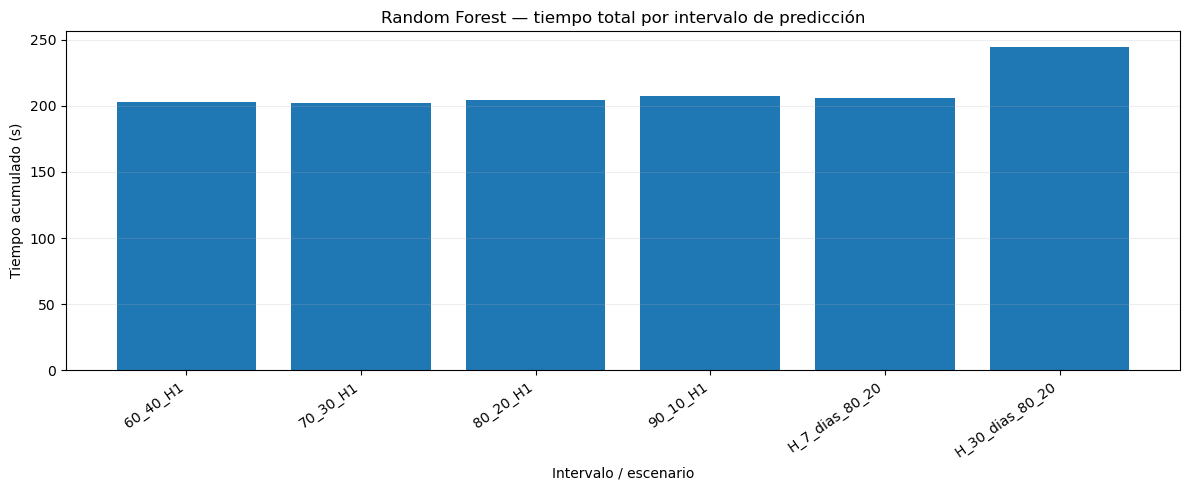

### Tiempo de código por partición porcentual

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
0,1,Particion porcentual,60_40_H1,1,60.0,40.0,2,199.0021,2.6723,0.7793,202.9186,101.4593,3.3820
1,2,Particion porcentual,70_30_H1,1,70.0,30.0,2,197.8923,2.7309,0.6921,201.7257,100.8629,3.3621
2,3,Particion porcentual,80_20_H1,1,80.0,20.0,2,199.2983,3.7499,0.9054,204.2959,102.1480,3.4049
3,4,Particion porcentual,90_10_H1,1,90.0,10.0,2,202.0676,4.3313,0.8925,207.6033,103.8016,3.4601


### Tiempo de código por horizonte fijo

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
4,5,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,2,200.1676,4.0225,1.0111,205.5216,102.7608,3.4254
5,6,Horizonte fijo,H_30_dias_80_20,30,80.0,20.0,2,239.2647,3.4977,0.8525,244.0805,122.0403,4.0680


### Configuración e hiperparámetros por intervalo

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,Hiperparametros_seleccionados,Tiempo_total_escenario_s,Tiempo_total_escenario_min,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Score_CV_alineado,Tipo_modelo_RF
0,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",101.877345,1.697956,6.707932,-0.092927,1.0,0.056490,residual_persistencia
1,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",101.041245,1.684021,2.096739,-0.152876,1.0,0.086804,residual_persistencia
2,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",100.363195,1.672720,7.032756,0.037286,1.0,0.057701,residual_persistencia
3,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",101.362514,1.689375,2.258229,-0.043925,1.0,0.007641,residual_persistencia
4,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",103.113979,1.718566,6.960384,-0.068483,1.0,0.062170,residual_persistencia
5,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",101.181928,1.686365,2.270937,-0.096495,1.0,0.043367,residual_persistencia
6,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",103.729884,1.728831,6.899621,0.014404,1.0,0.068997,residual_persistencia
7,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",103.873375,1.731223,2.277318,-0.075552,1.0,0.000000,residual_persistencia
8,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""bootstrap"": true, ""max_depth"": null, ""max_fe...",101.964144,1.699402,7.271352,-0.188312,3.0,0.009524,directo
9,PM25,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",103.557476,1.725958,2.345065,-0.190357,3.6,0.000000,directo


In [40]:
# V3_TIEMPOS_POR_INTERVALO
# ============================================================
# TIEMPOS POR INTERVALO / ESCENARIO + CONFIGURACIÓN E HIPERPARÁMETROS
# ============================================================

_detalle_tiempos_rf = tiempos_rf_df.copy()
_detalle_tiempos_rf["Test_nominal_%"] = 100.0 - _detalle_tiempos_rf["Train_nominal_%"].astype(float)

columnas_detalle_rf = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Orden_escenario",
    "Horizonte_dias", "Train_nominal_%", "Test_nominal_%", "Train_efectivo_%", "Test_efectivo_%",
    "Gap_purga_dias", "N_train", "N_test", "N_features",
    "Tiempo_validacion_CV_s", "Tiempo_entrenamiento_final_s", "Tiempo_prediccion_s",
    "Tiempo_total_escenario_s", "Tiempo_total_escenario_min",
    "Hiperparametros_seleccionados"
]
# Algunas columnas específicas del modelo pueden agregarse si existen.
for _c in ["Tipo_modelo_RF", "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Score_CV_alineado"]:
    if _c in _detalle_tiempos_rf.columns and _c not in columnas_detalle_rf:
        columnas_detalle_rf.append(_c)
columnas_detalle_rf = [_c for _c in columnas_detalle_rf if _c in _detalle_tiempos_rf.columns]

detalle_tiempos_intervalos_rf_df = (
    _detalle_tiempos_rf[columnas_detalle_rf]
    .sort_values(["Orden_escenario", "Variable", "Estacion"])
    .reset_index(drop=True)
)

resumen_tiempos_intervalos_rf_df = (
    _detalle_tiempos_rf
    .groupby([
        "Orden_escenario", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
        "Train_nominal_%", "Test_nominal_%"
    ], as_index=False)
    .agg(
        N_configuraciones=("Escenario", "size"),
        Tiempo_CV_acumulado_s=("Tiempo_validacion_CV_s", "sum"),
        Tiempo_entrenamiento_acumulado_s=("Tiempo_entrenamiento_final_s", "sum"),
        Tiempo_prediccion_acumulado_s=("Tiempo_prediccion_s", "sum"),
        Tiempo_total_intervalo_s=("Tiempo_total_escenario_s", "sum"),
        Tiempo_promedio_configuracion_s=("Tiempo_total_escenario_s", "mean"),
    )
    .sort_values("Orden_escenario")
    .reset_index(drop=True)
)
resumen_tiempos_intervalos_rf_df["Tiempo_total_intervalo_min"] = resumen_tiempos_intervalos_rf_df["Tiempo_total_intervalo_s"] / 60.0

# Tabla específica solicitada para 60/40, 70/30, 80/20 y 90/10.
tiempos_particiones_rf_df = resumen_tiempos_intervalos_rf_df[
    resumen_tiempos_intervalos_rf_df["Tipo_evaluacion"] == "Particion porcentual"
].copy()

# Tabla específica para horizontes fijos de 7, 30 y 90 días.
tiempos_horizontes_rf_df = resumen_tiempos_intervalos_rf_df[
    resumen_tiempos_intervalos_rf_df["Tipo_evaluacion"] == "Horizonte fijo"
].copy()

# Hiperparámetros efectivamente seleccionados en cada intervalo, por estación/variable.
configuracion_por_intervalo_rf_df = detalle_tiempos_intervalos_rf_df[[
    _c for _c in [
        "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
        "Train_nominal_%", "Test_nominal_%", "Hiperparametros_seleccionados",
        "Tiempo_total_escenario_s", "Tiempo_total_escenario_min",
        "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Score_CV_alineado",
        "Tipo_modelo_RF"
    ] if _c in detalle_tiempos_intervalos_rf_df.columns
]].copy()

# Exportaciones CSV independientes, listas para compartir y auditar.
ruta_resumen_tiempos_rf = TABLAS_RF / "RF_TIEMPOS_POR_INTERVALO.csv"
ruta_detalle_tiempos_rf = TABLAS_RF / "RF_DETALLE_TIEMPOS_CONFIGURACION_POR_INTERVALO.csv"
ruta_config_intervalo_rf = TABLAS_RF / "RF_CONFIGURACION_HIPERPARAMETROS_POR_INTERVALO.csv"

resumen_tiempos_intervalos_rf_df.to_csv(ruta_resumen_tiempos_rf, index=False, encoding="utf-8-sig")
detalle_tiempos_intervalos_rf_df.to_csv(ruta_detalle_tiempos_rf, index=False, encoding="utf-8-sig")
configuracion_por_intervalo_rf_df.to_csv(ruta_config_intervalo_rf, index=False, encoding="utf-8-sig")

# Figura concisa del costo computacional por intervalo.
plt.figure(figsize=(12, 5))
plt.bar(resumen_tiempos_intervalos_rf_df["Escenario"], resumen_tiempos_intervalos_rf_df["Tiempo_total_intervalo_s"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Tiempo acumulado (s)")
plt.xlabel("Intervalo / escenario")
plt.title("Random Forest — tiempo total por intervalo de predicción")
plt.grid(axis="y", alpha=0.22)
plt.tight_layout()
plt.savefig(GRAFICAS_RF / "RF_tiempo_total_por_intervalo.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Estas son las tablas que deben aparecer al final del notebook.
display(Markdown("### Tiempo de código por partición porcentual"))
display(tiempos_particiones_rf_df.round(4))
display(Markdown("### Tiempo de código por horizonte fijo"))
display(tiempos_horizontes_rf_df.round(4))
display(Markdown("### Configuración e hiperparámetros por intervalo"))
display(configuracion_por_intervalo_rf_df)


In [41]:

# ============================================================
# 13. EXPORTACIÓN, TRAZABILIDAD Y TIEMPO TOTAL
# ============================================================

# Hiperparámetros finalmente seleccionados por escenario.
hiperparametros_seleccionados_rf = tiempos_rf_df[[
    "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
    "Tipo_modelo_RF", "Hiperparametros_seleccionados"
]].drop_duplicates().sort_values(["Variable", "Estacion", "Horizonte_dias"])

# Exportación CSV.
archivos_rf = {
    "metricas_tesis": TABLAS_RF / "RF_metricas_prueba_tesis.csv",
    "metricas_maestro": TABLAS_RF / "RF_METRICAS_MAESTRO_COMPARACION.csv",
    "tiempos_tesis": TABLAS_RF / "RF_tiempos_configuracion_hiperparametros.csv",
    "predicciones": TABLAS_RF / "RF_predicciones_prueba.csv",
    "cv_resumen": TABLAS_RF / "RF_validacion_temporal_resumen.csv",
    "cv_folds": TABLAS_RF / "RF_validacion_temporal_folds.csv",
    "importancias": TABLAS_RF / "RF_importancia_variables.csv",
    "mejores": TABLAS_RF / "RF_mejor_escenario_por_estacion.csv",
    "escenarios": TABLAS_RF / "RF_escenarios.csv",
    "hiperparametros_candidatos": TABLAS_RF / "RF_hiperparametros_candidatos.csv",
    "hiperparametros_seleccionados": TABLAS_RF / "RF_hiperparametros_seleccionados.csv",
    "auditoria": TABLAS_RF / "RF_auditoria_supervisado.csv",
    "versiones": TABLAS_RF / "RF_versiones_entorno.csv",
    "residuales_resumen": TABLAS_RF / "RF_resumen_residuales.csv",
}

# CSV maestro: una fila por escenario con métricas + tiempos + configuración + alineación.
claves_maestro_rf = ["Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"]
metricas_maestro_rf = metricas_prueba_rf_df.merge(
    tiempos_rf_df,
    on=claves_maestro_rf,
    how="left",
    suffixes=("", "_tiempo")
)
metricas_maestro_rf["Es_mejor_observado_por_horizonte"] = False
claves_mejor_rf = set(zip(
    mejor_rf["Variable"], mejor_rf["Estacion"],
    mejor_rf["Horizonte_dias"], mejor_rf["Escenario"]
))
metricas_maestro_rf["Es_mejor_observado_por_horizonte"] = [
    (v, e, h, esc) in claves_mejor_rf
    for v, e, h, esc in zip(
        metricas_maestro_rf["Variable"], metricas_maestro_rf["Estacion"],
        metricas_maestro_rf["Horizonte_dias"], metricas_maestro_rf["Escenario"]
    )
]

tabla_metricas_tesis_rf.to_csv(archivos_rf["metricas_tesis"], index=False, encoding="utf-8-sig")
metricas_maestro_rf.to_csv(archivos_rf["metricas_maestro"], index=False, encoding="utf-8-sig")
tabla_tiempos_tesis_rf.to_csv(archivos_rf["tiempos_tesis"], index=False, encoding="utf-8-sig")
predicciones_rf_df.to_csv(archivos_rf["predicciones"], index=False, encoding="utf-8-sig")
cv_resumen_rf_df.to_csv(archivos_rf["cv_resumen"], index=False, encoding="utf-8-sig")
cv_folds_rf_df.to_csv(archivos_rf["cv_folds"], index=False, encoding="utf-8-sig")
importancias_rf_df.to_csv(archivos_rf["importancias"], index=False, encoding="utf-8-sig")
mejor_rf.to_csv(archivos_rf["mejores"], index=False, encoding="utf-8-sig")
escenarios_rf_df.to_csv(archivos_rf["escenarios"], index=False, encoding="utf-8-sig")
hiperparametros_rf_df.to_csv(archivos_rf["hiperparametros_candidatos"], index=False, encoding="utf-8-sig")
hiperparametros_seleccionados_rf.to_csv(archivos_rf["hiperparametros_seleccionados"], index=False, encoding="utf-8-sig")
auditoria_rf_df.to_csv(archivos_rf["auditoria"], index=False, encoding="utf-8-sig")
versiones_rf_df.to_csv(archivos_rf["versiones"], index=False, encoding="utf-8-sig")
resumen_residuales_rf.to_csv(archivos_rf["residuales_resumen"], index=False, encoding="utf-8-sig")

# Libro Excel consolidado.
ruta_excel_rf = SALIDAS_RF / "RF_RESUMEN_TESIS.xlsx"
with pd.ExcelWriter(ruta_excel_rf, engine="openpyxl") as writer:
    metricas_maestro_rf.to_excel(writer, sheet_name="metricas_maestro", index=False)
    tabla_metricas_tesis_rf.to_excel(writer, sheet_name="metricas_prueba", index=False)
    tabla_tiempos_tesis_rf.to_excel(writer, sheet_name="tiempos_config", index=False)
    mejor_rf.to_excel(writer, sheet_name="mejores", index=False)
    resumen_escenarios_rf.to_excel(writer, sheet_name="resumen_escenarios", index=False)
    hiperparametros_rf_df.to_excel(writer, sheet_name="hp_candidatos", index=False)
    hiperparametros_seleccionados_rf.to_excel(writer, sheet_name="hp_seleccionados", index=False)
    cv_resumen_rf_df.to_excel(writer, sheet_name="cv_resumen", index=False)
    auditoria_rf_df.to_excel(writer, sheet_name="auditoria", index=False)
    versiones_rf_df.to_excel(writer, sheet_name="versiones", index=False)
    resumen_residuales_rf.to_excel(writer, sheet_name="residuales", index=False)
    tiempos_particiones_rf_df.to_excel(writer, sheet_name="tiempos_particiones", index=False)
    tiempos_horizontes_rf_df.to_excel(writer, sheet_name="tiempos_horizontes", index=False)
    configuracion_por_intervalo_rf_df.to_excel(writer, sheet_name="config_por_intervalo", index=False)

TIEMPO_FIN_NOTEBOOK = time.perf_counter()
FECHA_HORA_FIN_NOTEBOOK = datetime.now()
TIEMPO_TOTAL_SEGUNDOS = TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK

tiempo_notebook_rf_df = pd.DataFrame([{
    "Notebook": "Random_Forest_TESIS",
    "Fecha_hora_inicio": FECHA_HORA_INICIO_NOTEBOOK,
    "Fecha_hora_fin": FECHA_HORA_FIN_NOTEBOOK,
    "Tiempo_total_segundos": TIEMPO_TOTAL_SEGUNDOS,
    "Tiempo_total_minutos": TIEMPO_TOTAL_SEGUNDOS / 60,
    "N_configuraciones_completadas": len(tiempos_rf_df),
}])

display(Markdown("## Tiempo total del notebook"))
display(tiempo_notebook_rf_df.round(4))

# RESUMEN FINAL SOLICITADO: TIEMPO POR CADA INTERVALO
display(Markdown("## Tiempo por cada intervalo de predicción"))
display(resumen_tiempos_intervalos_rf_df.round(4))
display(Markdown("### Detalle de configuración e hiperparámetros por intervalo"))
display(configuracion_por_intervalo_rf_df)
tiempo_notebook_rf_df.to_csv(TABLAS_RF / "RF_tiempo_total_notebook.csv", index=False, encoding="utf-8-sig")

print("Exportación finalizada.")
print("Carpeta:", SALIDAS_RF.resolve())
print("Excel:", ruta_excel_rf.resolve())


## Tiempo total del notebook

,Notebook,Fecha_hora_inicio,Fecha_hora_fin,Tiempo_total_segundos,Tiempo_total_minutos,N_configuraciones_completadas
0,Random_Forest_TESIS,2026-08-13 00:23:37.817923,2026-08-13 00:45:47.054841,1329.2369,22.1539,12


## Tiempo por cada intervalo de predicción

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
0,1,Particion porcentual,60_40_H1,1,60.0,40.0,2,199.0021,2.6723,0.7793,202.9186,101.4593,3.3820
1,2,Particion porcentual,70_30_H1,1,70.0,30.0,2,197.8923,2.7309,0.6921,201.7257,100.8629,3.3621
2,3,Particion porcentual,80_20_H1,1,80.0,20.0,2,199.2983,3.7499,0.9054,204.2959,102.1480,3.4049
3,4,Particion porcentual,90_10_H1,1,90.0,10.0,2,202.0676,4.3313,0.8925,207.6033,103.8016,3.4601
4,5,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,2,200.1676,4.0225,1.0111,205.5216,102.7608,3.4254
5,6,Horizonte fijo,H_30_dias_80_20,30,80.0,20.0,2,239.2647,3.4977,0.8525,244.0805,122.0403,4.0680


### Detalle de configuración e hiperparámetros por intervalo

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,Hiperparametros_seleccionados,Tiempo_total_escenario_s,Tiempo_total_escenario_min,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Score_CV_alineado,Tipo_modelo_RF
0,PM10,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",101.877345,1.697956,6.707932,-0.092927,1.0,0.056490,residual_persistencia
1,PM25,PALMIRA,Particion porcentual,60_40_H1,1,60.0,40.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",101.041245,1.684021,2.096739,-0.152876,1.0,0.086804,residual_persistencia
2,PM10,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",100.363195,1.672720,7.032756,0.037286,1.0,0.057701,residual_persistencia
3,PM25,PALMIRA,Particion porcentual,70_30_H1,1,70.0,30.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",101.362514,1.689375,2.258229,-0.043925,1.0,0.007641,residual_persistencia
4,PM10,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",103.113979,1.718566,6.960384,-0.068483,1.0,0.062170,residual_persistencia
5,PM25,PALMIRA,Particion porcentual,80_20_H1,1,80.0,20.0,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",101.181928,1.686365,2.270937,-0.096495,1.0,0.043367,residual_persistencia
6,PM10,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""bootstrap"": true, ""max_depth"": 12, ""max_feat...",103.729884,1.728831,6.899621,0.014404,1.0,0.068997,residual_persistencia
7,PM25,PALMIRA,Particion porcentual,90_10_H1,1,90.0,10.0,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",103.873375,1.731223,2.277318,-0.075552,1.0,0.000000,residual_persistencia
8,PM10,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""bootstrap"": true, ""max_depth"": null, ""max_fe...",101.964144,1.699402,7.271352,-0.188312,3.0,0.009524,directo
9,PM25,PALMIRA,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,"{""bootstrap"": true, ""max_depth"": 16, ""max_feat...",103.557476,1.725958,2.345065,-0.190357,3.6,0.000000,directo


Exportación finalizada.
Carpeta: C:\Users\santi\Prediccion_Cali_3_Version\salidas_RF_TESIS_PROTOCOLO_TEMPORAL
Excel: C:\Users\santi\Prediccion_Cali_3_Version\salidas_RF_TESIS_PROTOCOLO_TEMPORAL\RF_RESUMEN_TESIS.xlsx



## Mejoras incorporadas respecto de la versión anterior

- Se corrigió la diferencia conceptual entre **tamaño de prueba** y **horizonte de pronóstico**.
- Se implementó pronóstico directo \(t+h\) para 7, 30 y 90 días.
- Se incorporó una purga temporal igual al horizonte en holdout y validación cruzada.
- Se eliminó la imputación bidireccional de la etapa de modelado para evitar que valores futuros completen el pasado.
- Se añadió comparación explícita contra persistencia.
- Se ampliaron las métricas con WAPE y sesgo medio.
- Se registran tiempos separados para selección de hiperparámetros, ajuste final y predicción.
- Se genera una tabla final ordenada con configuración e hiperparámetros seleccionados.
- Las figuras del notebook se reducen a comparativos de alto valor analítico y al mejor escenario por estación/contaminante.
- Se exportan versiones del entorno para reproducibilidad.

- Se añadieron figuras de entrenamiento, prueba real y predicción para **cada intervalo**, con el residual `Real - Predicción` inmediatamente debajo.
- El tiempo de ejecución se resume ahora por 60/40, 70/30, 80/20, 90/10, H=7, H=30 y H=90, además del total global.
